# Taller 2 — Machine Learning Applied
## Red neuronal profunda (MLP) desde cero en PyTorch: resistencia a la compresión del concreto

**Curso:** ST1613 Applied Machine Learning
**Integrantes:** Equipo 3 — Jorge Andrés Durán y Juan Miguel Castro
**Competencia:** [Concrete Strength Regression (Kaggle)](https://www.kaggle.com/competitions/concrete-strength-regression)
**Framework:** PyTorch · **Fecha:** 2026

---

### Objetivo

Construir, entrenar y evaluar una **red neuronal *fully connected* (MLP) implementada desde cero en PyTorch** que
prediga la resistencia a la compresión del concreto a partir de su dosificación y su edad, integrando en un solo
flujo: EDA, limpieza, preprocesamiento sin fuga de datos, `Dataset`/`DataLoader` propios, entrenamiento con early
stopping, experimentación con validación cruzada K-Fold, comparación contra *baselines* y generación de la
submission para Kaggle.

### Planteamiento del problema

La resistencia a la compresión (MPa) es la propiedad de diseño más importante del concreto, pero se mide con un
**ensayo destructivo** sobre probetas que deben curarse durante días o semanas (28 días es la edad de referencia).
Un modelo que estime la resistencia a partir de la dosificación —kg/m³ de siete componentes— y de la edad permite
descartar mezclas antes de fabricarlas y ensayarlas.

- **Variable objetivo:** `csMPa`, resistencia en MPa, numérica y continua ⇒ **regresión supervisada**.
- **Métrica oficial:** MSE (MPa²), menor es mejor. Como `nn.MSELoss()` optimiza exactamente esa cantidad, es
  la función de pérdida natural.

Conocimiento de dominio que usaremos **sólo como hipótesis** a contrastar con los datos (no como hechos sobre este
dataset): (i) *ley de Abrams*: a mayor relación agua/cemento, menor resistencia; (ii) la resistencia crece con la
edad por la hidratación del cemento, rápido al principio y cada vez más despacio; (iii) la escoria (`slag`) y la
ceniza volante (`flyash`) son materiales cementantes suplementarios cuya ganancia de resistencia es más lenta.

### Mapa del notebook

| Sección | Contenido | Parte del enunciado |
|---|---|---|
| 0 | Configuración reproducible (semillas, dispositivo, estilo) | Recomendaciones |
| 1 | Carga y validación de los archivos | Parte 1.1 |
| 2 | EDA de reconocimiento y hallazgos | Parte 1 |
| 3 | Limpieza: duplicados | Partes 1.3 y 2 |
| 4 | Preprocesamiento y estrategia de evaluación | Parte 2 |
| 5 | `Dataset` y `DataLoader` | Parte 3 |
| 6 | Arquitectura de la MLP | Parte 4 |
| 7 | Entrenamiento y validación del modelo base | Parte 5 |
| 8 | *Baselines* y experimentos con K-Fold | Parte 6 |
| 9 | Evaluación final del modelo seleccionado | Partes 6 y 7 |
| 10 | Reentrenamiento, predicción y submission | Parte 7 |
| 11 | Conclusiones | Entregable 4 |

### Cómo ejecutar

La celda 1.1 localiza los tres CSV (`train.csv`, `test.csv`, `sample_submission.csv`) por sí sola; **ninguna otra
celda contiene rutas**, y en local nunca intenta montar Google Drive.

**Opción A — local (VS Code o Jupyter).**
1. Usar el repositorio tal como está: el notebook en la raíz y los tres CSV en `data/`.
2. Seleccionar como kernel un entorno con las dependencias de `requirements.txt`. Este notebook se ejecutó con el
   entorno aislado `.venv-taller2` (versiones impresas en la celda 0).
3. **Restart → Run All.**

**Opción B — Google Colab.**
1. *(Opcional)* **Entorno de ejecución → Cambiar tipo de entorno → GPU**; el código funciona igual en CPU.
2. **Con Drive:** subir la carpeta completa del proyecto (con su carpeta `data/`) a **Mi unidad** y abrir el notebook
   desde allí. La celda 1.1 monta Drive (pide autorización una vez) y busca la carpeta
   `workshop-2-concrete-strength-mlp` o `taller2-machine-learning-main` en *Mi unidad* o un nivel más abajo. Si está en
   otro lugar o tiene otro nombre, basta con corregir `CARPETA_DRIVE`, la única ruta editable.
3. **Sin Drive:** subir los tres CSV a `/content` con el panel **Archivos**; si tampoco están ahí, la celda abre un
   selector de archivos.
4. **Entorno de ejecución → Reiniciar y ejecutar todo.**

En ambos casos, la ejecución completa escribe `submission.csv` en la **raíz del proyecto**, no dentro de `data/`
(sección 10.3).
`FORMATO_KAGGLE_CONFIRMADO = True`: el formato quedó confirmado al enviar este archivo a Kaggle (sección 10.4).

> **Reproducibilidad:** todas las particiones, inicializaciones y órdenes de *batches* derivan de `SEED = 42`.
>
> **Estado del documento.** Las salidas guardadas provienen de una **ejecución completa desde un kernel nuevo**, en
> local y en CPU (versiones en la celda 0), y todas las interpretaciones citan esas salidas. En CPU, con las mismas
> versiones, las métricas se reprodujeron exactamente en ejecuciones independientes; en otro entorno (p. ej., la GPU
> de Colab) pueden variar ligeramente. La evaluación externa en Kaggle (**Public Score 24.81485**, envío posterior al
> cierre de la competencia) se registra en la sección 10.4; sus capturas están en `docs/evidence/` del repositorio.

---
# 0. Configuración reproducible

Se importan las librerías (todas preinstaladas en Colab: no se instala nada), se fijan las semillas, se detecta
el dispositivo y se define el estilo de las gráficas —la misma paleta validada para daltonismo del Taller 1—.

Las constantes de entrenamiento (`MAX_EPOCAS`, `PACIENCIA`, `N_FOLDS`) se definen aquí una sola vez para que todos
los experimentos compartan exactamente las mismas condiciones. `MODO_RAPIDO = True` sólo sirve para comprobar que
el notebook corre de punta a punta en pocos minutos; **sus resultados no son válidos para el informe** y el
notebook lo advierte en cada tabla de resultados.

In [1]:
import os
import sys
import copy
import math
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader, RandomSampler, SequentialSampler

import sklearn
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ---------------- Constantes del experimento ----------------
SEED = 42
MODO_RAPIDO = False            # True sólo para una prueba de humo: resultados NO válidos para el informe
N_FOLDS = 2 if MODO_RAPIDO else 5
MAX_EPOCAS = 60 if MODO_RAPIDO else 1000
PACIENCIA = 10 if MODO_RAPIDO else 60   # épocas sin mejorar la pérdida de validación antes de detener
MIN_DELTA = 1e-4                        # mejora mínima (en unidades estandarizadas) para contar como mejora
FRACCION_ES = 0.15                      # fracción interna para early stopping dentro de cada fold

ID_COL = "Row ID"
TARGET = "csMPa"
COMPONENTES = ["cement", "slag", "flyash", "water", "superplasticizer", "coarseaggregate", "fineaggregate"]
PREDICTORES = COMPONENTES + ["age"]
UNIDADES = {c: "kg/m³" for c in COMPONENTES} | {"age": "días", TARGET: "MPa"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fijar_semillas(seed):
    """Fija las semillas de Python, NumPy y PyTorch (CPU y CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


fijar_semillas(SEED)

# ---------------- Estilo de gráficas (mismo sistema visual que el Taller 1) ----------------
PALETA = ["#2563EB", "#D97706", "#0D9488", "#BE123C", "#7C3AED"]
TINTA, TINTA_SUAVE, REJILLA = "#1F2328", "#57606A", "#D8DEE4"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.linewidth": 1.0,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.alpha": 0.7,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": TINTA,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE, "legend.frameon": False,
})


def etiqueta(col):
    return f"{col} ({UNIDADES[col]})" if col in UNIDADES else col


print(f"Python {sys.version.split()[0]} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scikit-learn {sklearn.__version__} · torch {torch.__version__} · matplotlib {matplotlib.__version__}")
print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print(f"MODO_RAPIDO = {MODO_RAPIDO} · N_FOLDS = {N_FOLDS} · MAX_EPOCAS = {MAX_EPOCAS} · PACIENCIA = {PACIENCIA}")
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO activo: los resultados sirven sólo para verificar que el notebook corre.")

Python 3.12.6 · numpy 2.5.4 · pandas 3.0.6 · scikit-learn 1.9.1 · torch 2.14.1+cpu · matplotlib 3.11.2
Dispositivo: cpu
MODO_RAPIDO = False · N_FOLDS = 5 · MAX_EPOCAS = 1000 · PACIENCIA = 60


---
# 1. Carga y validación de los archivos

### 1.1 Localización de los CSV

En el repositorio, los tres CSV de entrada están en la carpeta `data/` y el notebook en la raíz. La celda recorre
varias carpetas raíz candidatas; en cada una busca primero `data/` y luego la propia raíz, y se detiene en la primera
carpeta que contiene **los tres** archivos:

1. **Local o `/content`:** la carpeta actual (la del notebook en VS Code/Jupyter), `workshop-2-concrete-strength-mlp/`
   o `taller2-machine-learning-main/` (si se ejecuta desde la carpeta superior) y `/content`.
2. **Google Drive (sólo en Colab):** si no los encontró, monta Drive y busca en `CARPETA_DRIVE` y en cualquier carpeta
   con uno de esos dos nombres ubicada en *Mi unidad* o un nivel más abajo.
3. **Subida manual (sólo en Colab):** si tampoco están en Drive, abre un selector de archivos.

`submission.csv` se escribe en la **raíz del proyecto** (`CARPETA_SALIDA`): la carpeta que contiene `data/` o, si los
CSV se subieron sueltos, esa misma carpeta. Si no encuentra los archivos, la celda se detiene con un error que indica
dónde buscó. Ninguna otra celda del notebook contiene rutas.

In [2]:
import glob

CARPETA_DRIVE = "/content/drive/MyDrive/workshop-2-concrete-strength-mlp"   # única ruta editable del notebook
ARCHIVOS = ["train.csv", "test.csv", "sample_submission.csv"]
NOMBRES_PROYECTO = ["workshop-2-concrete-strength-mlp", "taller2-machine-learning-main"]

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False


def buscar_carpeta_datos(raices):
    """Para cada raíz candidata busca los tres CSV en raíz/data/ y, si no, en la propia raíz."""
    for raiz in raices:
        for carpeta in (os.path.join(raiz, "data"), raiz):
            if all(os.path.isfile(os.path.join(carpeta, f)) for f in ARCHIVOS):
                return os.path.normpath(carpeta)
    return None


# 1) Local (VS Code/Jupyter, con el repositorio clonado) o archivos ya subidos a /content
RAICES_LOCALES = ["."] + NOMBRES_PROYECTO + ["/content"]
CARPETA_DATOS = buscar_carpeta_datos(RAICES_LOCALES)
RAICES_DRIVE = []

# 2) Colab + Google Drive
if CARPETA_DATOS is None and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAICES_DRIVE = [CARPETA_DRIVE] + [ruta for nombre in NOMBRES_PROYECTO
                                      for patron in ("/content/drive/MyDrive/" + nombre, "/content/drive/MyDrive/*/" + nombre)
                                      for ruta in sorted(glob.glob(patron))]
    CARPETA_DATOS = buscar_carpeta_datos(RAICES_DRIVE)

# 3) Colab sin Drive: subida manual a /content
if CARPETA_DATOS is None and EN_COLAB:
    from google.colab import files
    print("No se encontraron los CSV. Selecciona train.csv, test.csv y sample_submission.csv:")
    files.upload()                      # los guarda en el directorio actual (/content)
    CARPETA_DATOS = buscar_carpeta_datos(["."])

if CARPETA_DATOS is None:
    buscadas = [os.path.abspath(c) for c in RAICES_LOCALES] + RAICES_DRIVE
    raise FileNotFoundError(
        "No se encontraron train.csv, test.csv y sample_submission.csv juntos (en data/ ni en la raíz) de ninguna "
        "de estas carpetas:\n  " + "\n  ".join(buscadas)
        + "\nLocal: ejecuta el notebook desde la raíz del repositorio clonado (con la carpeta data/). Colab: sube la "
          "carpeta del proyecto a Mi unidad (o corrige CARPETA_DRIVE), o sube los tres CSV a /content.")

# submission.csv se escribe en la raíz del proyecto: la carpeta que contiene data/ (o la de los CSV si no hay data/)
CARPETA_SALIDA = (os.path.dirname(CARPETA_DATOS) or ".") if os.path.basename(CARPETA_DATOS) == "data" else CARPETA_DATOS
# Se imprimen rutas relativas (o las de Drive en Colab) para no exponer rutas personales del equipo
print("Carpeta de datos  :", CARPETA_DATOS)
print("Carpeta de salida :", CARPETA_SALIDA, "(raíz del proyecto: aquí se escribirá submission.csv)")

Carpeta de datos  : data
Carpeta de salida : . (raíz del proyecto: aquí se escribirá submission.csv)


### 1.2 Lectura y comprobación de supuestos críticos

Antes de cualquier análisis se verifican explícitamente los supuestos de los que depende todo el notebook:
columnas y orden esperados, objetivo presente sólo en train, dimensiones, tipos numéricos, ausencia de faltantes e
infinitos, e identificadores únicos y disjuntos entre train y test.

In [3]:
train_raw = pd.read_csv(os.path.join(CARPETA_DATOS, "train.csv"))
test_raw = pd.read_csv(os.path.join(CARPETA_DATOS, "test.csv"))
sample_sub = pd.read_csv(os.path.join(CARPETA_DATOS, "sample_submission.csv"))

COLUMNAS_TRAIN = [ID_COL] + PREDICTORES + [TARGET]
COLUMNAS_TEST = [ID_COL] + PREDICTORES

assert list(train_raw.columns) == COLUMNAS_TRAIN, f"Columnas de train inesperadas: {list(train_raw.columns)}"
assert list(test_raw.columns) == COLUMNAS_TEST, f"Columnas de test inesperadas: {list(test_raw.columns)}"
assert TARGET in train_raw.columns and TARGET not in test_raw.columns
assert list(train_raw[PREDICTORES].columns) == list(test_raw[PREDICTORES].columns)   # mismo orden de predictores
assert train_raw.shape == (721, 10), train_raw.shape     # dimensiones documentadas en el diagnóstico
assert test_raw.shape == (309, 9), test_raw.shape

for nombre, df in [("train", train_raw), ("test", test_raw)]:
    assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes), f"{nombre}: hay columnas no numéricas"
    assert df.isna().sum().sum() == 0, f"{nombre}: hay valores faltantes"
    assert np.isfinite(df.to_numpy(dtype=float)).all(), f"{nombre}: hay valores infinitos"
    assert df[ID_COL].is_unique, f"{nombre}: Row ID repetido"
assert set(train_raw[ID_COL]).isdisjoint(test_raw[ID_COL]), "Row ID compartido entre train y test"

print("✅ Supuestos verificados")
print(f"   train: {train_raw.shape} · Row ID {train_raw[ID_COL].min()}–{train_raw[ID_COL].max()}")
print(f"   test : {test_raw.shape} · Row ID {test_raw[ID_COL].min()}–{test_raw[ID_COL].max()}")
print(f"   predictores ({len(PREDICTORES)}): {PREDICTORES}")

✅ Supuestos verificados
   train: (721, 10) · Row ID 0–720
   test : (309, 9) · Row ID 721–1029
   predictores (8): ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age']


### 1.3 La plantilla `sample_submission.csv` no representa la submission completa

El diagnóstico previo encontró que este archivo tiene muy pocas filas y que sus `Row ID` no corresponden a test.
La celda lo comprueba. **Consecuencia:** de la plantilla sólo se toman el **nombre y el orden de las columnas**.
La submission tiene una predicción por cada fila de `test.csv`, como indica el enunciado. Ese formato se confirmó
después con la propia competencia: Kaggle procesó y puntuó el archivo de 309 filas (secciones 10.3 y 10.4).

In [4]:
assert list(sample_sub.columns) == [ID_COL, TARGET], f"Columnas de la plantilla inesperadas: {list(sample_sub.columns)}"
ids_sample = set(sample_sub[ID_COL])
print("Columnas de la plantilla:", list(sample_sub.columns))
print("Filas de la plantilla   :", len(sample_sub), "| filas de test:", len(test_raw))
print("Row ID de la plantilla presentes en train:", len(ids_sample & set(train_raw[ID_COL])),
      "| presentes en test:", len(ids_sample & set(test_raw[ID_COL])))
print("Valores de la plantilla :", sample_sub[TARGET].tolist())
display(sample_sub)

Columnas de la plantilla: ['Row ID', 'csMPa']
Filas de la plantilla   : 10 | filas de test: 309
Row ID de la plantilla presentes en train: 10 | presentes en test: 0
Valores de la plantilla : [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]


,Row ID,csMPa
0,136,3.0000
1,141,4.0000
2,164,5.0000
3,262,6.0000
4,247,7.0000
5,51,8.0000
6,10,9.0000
7,225,10.0000
8,2,11.0000
9,158,12.0000


---
# 2. EDA de reconocimiento (Parte 1)

### 2.1 Estructura, tipos y diccionario de datos

| Columna | Descripción | Unidad | Rol |
|---|---|---|---|
| `Row ID` | Identificador de la fila (0–720 en train, 721–1029 en test) | — | **No predictor**; se conserva para la submission |
| `cement` | Cemento (componente 1) | kg/m³ de mezcla | Predictor |
| `slag` | Escoria de alto horno (componente 2) | kg/m³ | Predictor |
| `flyash` | Ceniza volante (componente 3) | kg/m³ | Predictor |
| `water` | Agua (componente 4) | kg/m³ | Predictor |
| `superplasticizer` | Superplastificante (componente 5) | kg/m³ | Predictor |
| `coarseaggregate` | Agregado grueso (componente 6) | kg/m³ | Predictor |
| `fineaggregate` | Agregado fino (componente 7) | kg/m³ | Predictor |
| `age` | Edad de la probeta al ensayo | días (1–365) | Predictor |
| `csMPa` | Resistencia a la compresión | MPa | **Objetivo** (sólo en train) |

In [5]:
print(f"train: {train_raw.shape[0]} filas × {train_raw.shape[1]} columnas | "
      f"test: {test_raw.shape[0]} filas × {test_raw.shape[1]} columnas\n")
train_raw.info()
print()
test_raw.info()
display(train_raw.head())
display(test_raw.head())

train: 721 filas × 10 columnas | test: 309 filas × 9 columnas

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            721 non-null    int64  
 1   cement            721 non-null    float64
 2   slag              721 non-null    float64
 3   flyash            721 non-null    float64
 4   water             721 non-null    float64
 5   superplasticizer  721 non-null    float64
 6   coarseaggregate   721 non-null    float64
 7   fineaggregate     721 non-null    float64
 8   age               721 non-null    int64  
 9   csMPa             721 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 56.5 KB

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            309 non-null    i

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,0,184.0000,86.0000,190.0000,213.0000,6.0000,923.0000,623.0000,28,22.9300
1,1,313.3000,145.0000,0.0000,178.5000,8.0000,"1,001.9000",688.7000,28,41.0500
2,2,387.0000,20.0000,94.0000,157.0000,13.9000,938.0000,845.0000,7,45.9000
3,3,162.0000,214.0000,164.0000,202.0000,10.0000,820.0000,680.0000,28,30.6500
4,4,252.3000,0.0000,98.8000,146.3000,14.2000,987.8000,889.0000,14,42.2900


,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age
0,721,167.4000,129.9000,128.6000,175.5000,7.8000,"1,006.3000",746.6000,14
1,722,255.5000,170.3000,0.0000,185.7000,0.0000,"1,026.6000",724.3000,28
2,723,246.8000,0.0000,125.1000,143.3000,12.0000,"1,086.8000",800.9000,3
3,724,318.8000,212.5000,0.0000,155.7000,14.3000,852.1000,880.4000,28
4,725,218.9000,0.0000,124.1000,158.5000,11.3000,"1,078.7000",794.9000,56


### 2.2 Estadísticas descriptivas

Además de `describe()` se añaden la asimetría, el porcentaje de ceros y el número de valores distintos, porque son
las tres propiedades que más condicionan el preprocesamiento de una red neuronal.

In [6]:
NUMERICAS = PREDICTORES + [TARGET]
desc = train_raw[NUMERICAS].describe().T
desc["asimetría"] = train_raw[NUMERICAS].skew()
desc["% ceros"] = (train_raw[NUMERICAS] == 0).mean() * 100
desc["valores distintos"] = train_raw[NUMERICAS].nunique()
desc.insert(0, "unidad", [UNIDADES[c] for c in NUMERICAS])
desc.round(2)

,unidad,count,mean,std,min,25%,50%,75%,max,asimetría,% ceros,valores distintos
cement,kg/m³,721.0000,280.6300,103.1100,102.0000,194.7000,273.0000,359.0000,540.0000,0.4400,0.0000,245
slag,kg/m³,721.0000,74.7400,85.7000,0.0000,0.0000,24.0000,142.8000,359.4000,0.7600,44.6600,153
flyash,kg/m³,721.0000,54.8700,63.3300,0.0000,0.0000,0.0000,118.2000,200.0000,0.5000,53.6800,131
water,kg/m³,721.0000,181.0300,21.5700,121.8000,164.9000,184.0000,192.0000,247.0000,0.0700,0.0000,174
superplasticizer,kg/m³,721.0000,6.5000,6.0000,0.0000,0.0000,6.9000,10.6000,32.2000,0.8100,34.5400,105
coarseaggregate,kg/m³,721.0000,971.4000,76.5200,801.0000,932.0000,967.0000,"1,028.4000","1,134.3000",-0.0400,0.0000,242
fineaggregate,kg/m³,721.0000,775.1300,78.8900,594.0000,734.0000,780.0000,825.0000,992.6000,-0.1900,0.0000,259
age,días,721.0000,44.9500,60.4300,1.0000,14.0000,28.0000,56.0000,365.0000,3.2800,0.0000,14
csMPa,MPa,721.0000,36.1600,17.2000,2.3300,23.3500,34.5700,47.7100,82.6000,0.3900,0.0000,626


**Interpretación.**

1. **Escalas muy distintas.** `coarseaggregate` vive entre ~800 y ~1 134 kg/m³ y `superplasticizer` entre 0 y
   ~32 kg/m³: dos órdenes de magnitud. Una red que recibiera estas variables sin escalar empezaría el
   entrenamiento con gradientes dominados por las variables grandes. **El escalamiento es indispensable.**
2. **`age` es la variable más asimétrica** (asimetría ≈ 3.3, mediana 28 días, máximo 365) y tiene **sólo 14
   valores distintos**: es una variable numérica discreta, concentrada en edades de ensayo estándar.
3. **Tres componentes tienen muchos ceros:** `slag` (≈ 45 %), `flyash` (≈ 54 %) y `superplasticizer` (≈ 35 %).
   Son *ceros estructurales* —la mezcla simplemente no usa ese componente— y no valores faltantes.
4. **El objetivo `csMPa` es casi simétrico** (asimetría ≈ 0.39, media ≈ 36.2 MPa, rango ≈ 2.3–82.6 MPa); a
   diferencia de la tarifa de Uber del Taller 1, no hay una cola larga que justifique transformarlo con logaritmo.

### 2.3 Valores faltantes, infinitos y duplicados

Se distinguen tres niveles de duplicación, porque implican decisiones distintas:
**(a)** filas idénticas incluyendo `Row ID` (imposible si el ID es único),
**(b)** filas idénticas en predictores **y** objetivo ignorando `Row ID` (copias exactas del mismo registro) y
**(c)** filas con los **mismos predictores pero distinta resistencia** (réplicas del mismo ensayo con resultados
diferentes).

In [7]:
for nombre, df in [("train", train_raw), ("test", test_raw)]:
    print(f"{nombre}: nulos = {int(df.isna().sum().sum())} · infinitos = {int(np.isinf(df.to_numpy(dtype=float)).sum())}")

print("\n(a) Filas duplicadas contando Row ID          :", int(train_raw.duplicated().sum()))
dup_exactos = train_raw.duplicated(subset=PREDICTORES + [TARGET], keep="first")
print("(b) Duplicados exactos (predictores + csMPa)   :", int(dup_exactos.sum()))

grupos = train_raw.groupby(PREDICTORES)[TARGET].agg(filas="size", valores_distintos="nunique",
                                                    minimo="min", maximo="max")
repetidos = grupos[grupos["filas"] > 1]
mismo_y = repetidos[repetidos["valores_distintos"] == 1]
conflictivos = repetidos[repetidos["valores_distintos"] > 1].assign(rango_MPa=lambda d: d["maximo"] - d["minimo"])

resumen_dup = pd.DataFrame({
    "grupos": [len(repetidos), len(mismo_y), len(conflictivos)],
    "filas involucradas": [int(repetidos["filas"].sum()), int(mismo_y["filas"].sum()), int(conflictivos["filas"].sum())],
}, index=["Vectores de predictores repetidos", "   … con csMPa idéntico", "(c) … con csMPa distinto"])
display(resumen_dup)
print("Grupos con el mismo vector de predictores y distinta resistencia:")
display(conflictivos.sort_values("rango_MPa", ascending=False).reset_index())

print("Vectores de predictores repetidos dentro de test:", int(test_raw.duplicated(subset=PREDICTORES).sum()))
claves_train = set(map(tuple, train_raw[PREDICTORES].to_numpy()))
en_train = np.array([tuple(fila) in claves_train for fila in test_raw[PREDICTORES].to_numpy()])
print("Filas de test cuyo vector de predictores aparece idéntico en train:", int(en_train.sum()))

train: nulos = 0 · infinitos = 0
test: nulos = 0 · infinitos = 0

(a) Filas duplicadas contando Row ID          : 0
(b) Duplicados exactos (predictores + csMPa)   : 16


,grupos,filas involucradas
Vectores de predictores repetidos,14,40
… con csMPa idéntico,7,22
(c) … con csMPa distinto,7,18


Grupos con el mismo vector de predictores y distinta resistencia:


,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,filas,valores_distintos,minimo,maximo,rango_MPa
0,362.6000,189.0000,0.0000,164.9000,11.6000,944.7000,755.8000,7,3,2,22.9000,55.9000,33.0000
1,446.0000,24.0000,79.0000,162.0000,11.6000,967.0000,712.0000,7,2,2,38.0200,52.0100,13.9900
2,446.0000,24.0000,79.0000,162.0000,11.6000,967.0000,712.0000,28,3,3,44.4200,57.0300,12.6100
3,446.0000,24.0000,79.0000,162.0000,11.6000,967.0000,712.0000,3,3,3,23.3500,35.3600,12.0100
4,446.0000,24.0000,79.0000,162.0000,11.6000,967.0000,712.0000,56,3,3,55.2500,61.0700,5.8200
5,359.0000,19.0000,141.0000,154.0000,10.9000,942.0000,801.0000,28,2,2,59.4900,62.9400,3.4500
6,359.0000,19.0000,141.0000,154.0000,10.9000,942.0000,801.0000,3,2,2,23.6400,25.1200,1.4800


Vectores de predictores repetidos dentro de test: 4
Filas de test cuyo vector de predictores aparece idéntico en train: 11


**Interpretación.** No hay faltantes ni infinitos en ningún archivo, como indica la documentación. En cambio, sí hay
duplicación: **16 filas son copias exactas** (mismos predictores y misma resistencia) de otra fila de train, y hay
**7 grupos (18 filas) con los mismos predictores pero resistencias distintas** —el caso más extremo pasa de
22.9 a 55.9 MPa para una misma mezcla a 7 días—. Este segundo fenómeno es información, no un error que corregir:
indica **ruido experimental irreducible** (dos probetas idénticas no dan la misma resistencia), y por tanto un piso
de error que ningún modelo puede bajar. La decisión sobre ambos casos se toma en la sección 3.

### 2.4 Tipos de variables e identificadores

In [8]:
roles = {ID_COL: "identificador (no predictor)", TARGET: "objetivo"}
tipos = pd.DataFrame({
    "dtype en train": train_raw.dtypes.astype(str),
    "dtype en test": test_raw.dtypes.astype(str).reindex(train_raw.columns).fillna("— (no existe)"),
    "rol": [roles.get(c, "predictor numérico") for c in train_raw.columns],
})
display(tipos)
print("Variables categóricas encontradas:", [c for c in train_raw.columns if not pd.api.types.is_numeric_dtype(train_raw[c])] or "ninguna")
print(f"Correlación Row ID vs csMPa — Pearson: {train_raw[ID_COL].corr(train_raw[TARGET]):.3f} · "
      f"Spearman: {train_raw[ID_COL].corr(train_raw[TARGET], method='spearman'):.3f}")
print("¿age toma sólo valores enteros?", bool((train_raw["age"] % 1 == 0).all() and (test_raw["age"] % 1 == 0).all()))

,dtype en train,dtype en test,rol
Row ID,int64,int64,identificador (no predictor)
cement,float64,float64,predictor numérico
slag,float64,float64,predictor numérico
flyash,float64,float64,predictor numérico
water,float64,float64,predictor numérico
superplasticizer,float64,float64,predictor numérico
coarseaggregate,float64,float64,predictor numérico
fineaggregate,float64,float64,predictor numérico
age,int64,int64,predictor numérico
csMPa,float64,— (no existe),objetivo


Variables categóricas encontradas: ninguna
Correlación Row ID vs csMPa — Pearson: -0.019 · Spearman: -0.021
¿age toma sólo valores enteros? True


**Interpretación.** Todas las variables son numéricas (`int64`/`float64`); **no existe ninguna variable categórica**.
`Row ID` es un identificador secuencial sin relación con la resistencia (correlación prácticamente nula, como
muestra la celda), así que se excluye de los predictores: un modelo que lo usara aprendería, en el mejor caso,
ruido, y en el peor, un artefacto del orden del archivo. Se conserva únicamente para identificar las predicciones
de test.

### 2.5 Distribución de la variable objetivo

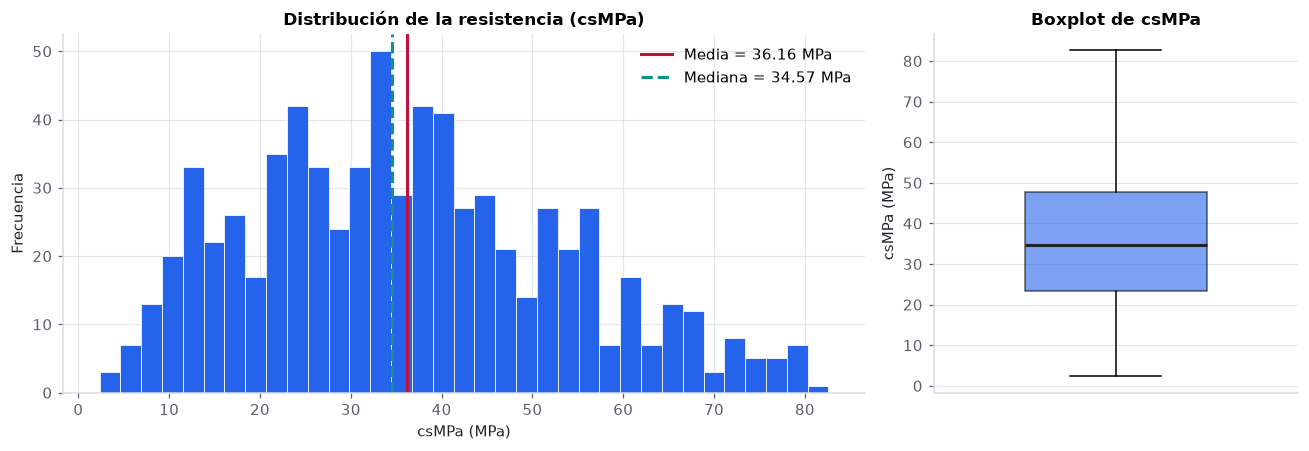

Asimetría: 0.391 · curtosis: -0.445


Límites IQR: [-13.19, 84.25] MPa · observaciones fuera: 0
Varianza de csMPa (MSE de predecir siempre la media, dentro de la muestra): 295.28 MPa²


In [9]:
y_raw = train_raw[TARGET]
q1, q3 = y_raw.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_atipicos = int(((y_raw < lim_inf) | (y_raw > lim_sup)).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].hist(y_raw, bins=35, color=PALETA[0], edgecolor="white", linewidth=0.5)
axes[0].axvline(y_raw.mean(), color=PALETA[3], lw=2, label=f"Media = {y_raw.mean():.2f} MPa")
axes[0].axvline(y_raw.median(), color=PALETA[2], lw=2, ls="--", label=f"Mediana = {y_raw.median():.2f} MPa")
axes[0].set_title("Distribución de la resistencia (csMPa)")
axes[0].set_xlabel(etiqueta(TARGET)); axes[0].set_ylabel("Frecuencia"); axes[0].legend()
axes[1].boxplot(y_raw, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor=PALETA[0], alpha=0.6), medianprops=dict(color=TINTA, lw=2))
axes[1].set_title("Boxplot de csMPa"); axes[1].set_ylabel(etiqueta(TARGET)); axes[1].set_xticks([])
fig.tight_layout(); plt.show()

print(f"Asimetría: {y_raw.skew():.3f} · curtosis: {y_raw.kurt():.3f}")
print(f"Límites IQR: [{lim_inf:.2f}, {lim_sup:.2f}] MPa · observaciones fuera: {n_atipicos}")
print(f"Varianza de csMPa (MSE de predecir siempre la media, dentro de la muestra): {y_raw.var(ddof=0):.2f} MPa²")

**Interpretación.** La resistencia es unimodal y casi simétrica: media y mediana están a menos de 2 MPa, la
asimetría es ≈ 0.39 y el criterio IQR **no marca ninguna observación atípica**. No hay valores que eliminar ni una
cola que transformar, así que el objetivo **no se transforma con logaritmo**. Sí se **estandarizará** (media 0,
desviación 1) sólo para entrenar, porque deja la salida de la red en una escala O(1), coherente con la
inicialización por defecto de PyTorch; las métricas siempre se reportan tras invertir esa transformación.

La última línea da una referencia útil: la varianza de `csMPa` (≈ 295 MPa²) es el MSE que obtendría un modelo
trivial que predijera siempre la media. Cualquier modelo útil debe quedar muy por debajo de ese valor.

### 2.6 Distribución de cada predictor

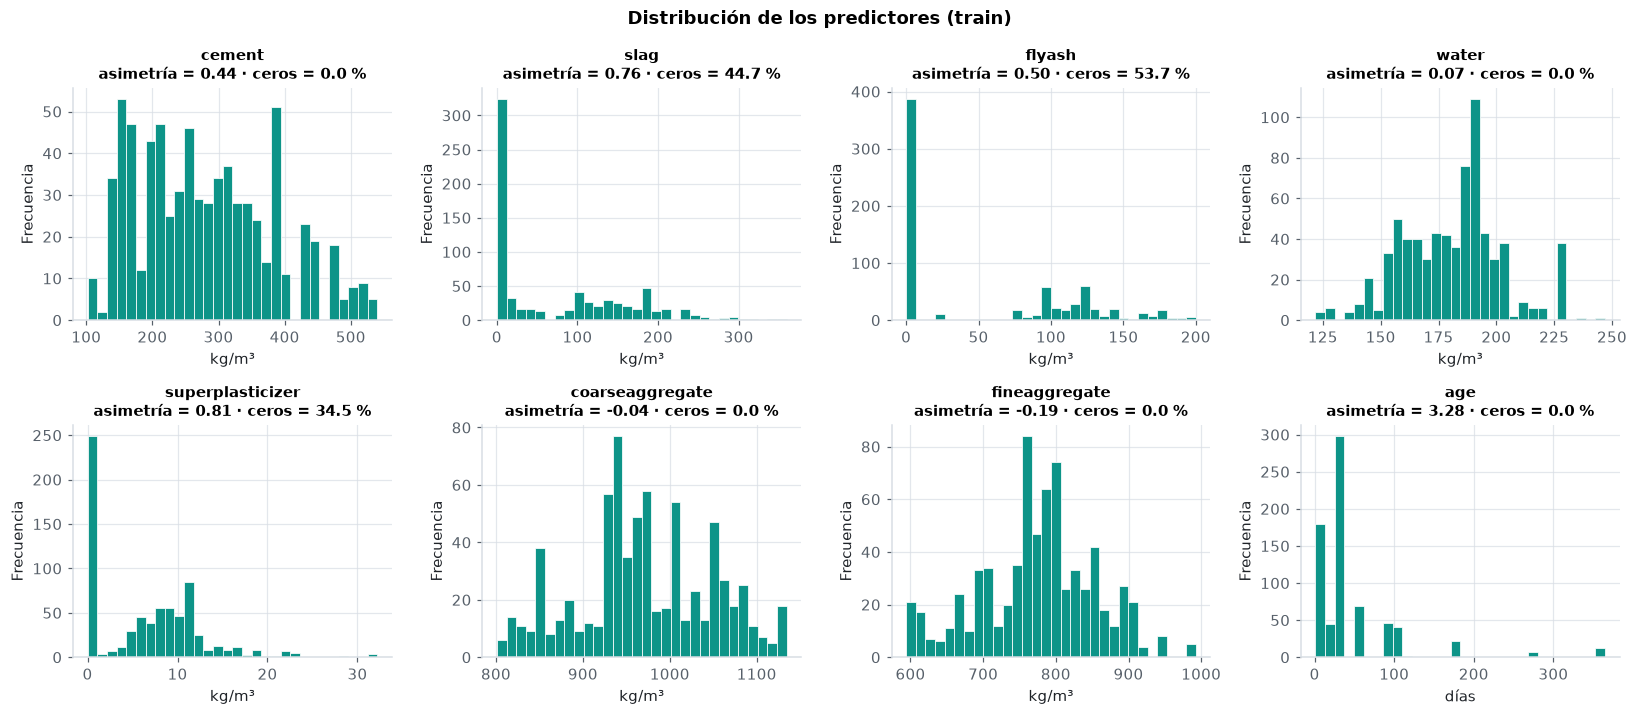

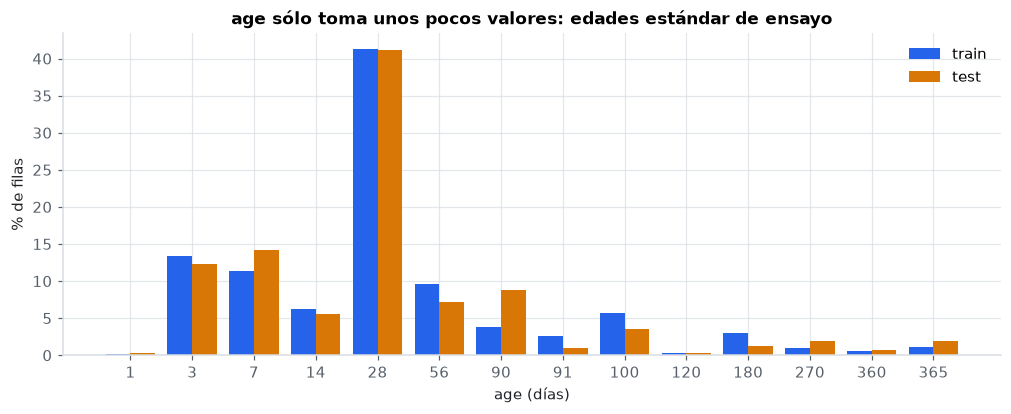

,train (n),test (n),train (%),test (%)
age,,,,
1,1,1,0.1000,0.3000
3,96,38,13.3000,12.3000
7,82,44,11.4000,14.2000
14,45,17,6.2000,5.5000
28,298,127,41.3000,41.1000
56,69,22,9.6000,7.1000
90,27,27,3.7000,8.7000
91,19,3,2.6000,1.0000
100,41,11,5.7000,3.6000


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for ax, col in zip(axes.ravel(), PREDICTORES):
    s = train_raw[col]
    ax.hist(s, bins=30, color=PALETA[2], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{col}\nasimetría = {s.skew():.2f} · ceros = {100 * (s == 0).mean():.1f} %", fontsize=10)
    ax.set_xlabel(UNIDADES[col]); ax.set_ylabel("Frecuencia")
fig.suptitle("Distribución de los predictores (train)", fontweight="bold")
fig.tight_layout(); plt.show()

edades = pd.DataFrame({
    "train (n)": train_raw["age"].value_counts().sort_index(),
    "test (n)": test_raw["age"].value_counts().sort_index(),
}).fillna(0).astype(int)
edades["train (%)"] = 100 * edades["train (n)"] / len(train_raw)
edades["test (%)"] = 100 * edades["test (n)"] / len(test_raw)

fig, ax = plt.subplots(figsize=(11, 3.8))
pos = np.arange(len(edades))
ax.bar(pos - 0.2, edades["train (%)"], width=0.4, color=PALETA[0], label="train")
ax.bar(pos + 0.2, edades["test (%)"], width=0.4, color=PALETA[1], label="test")
ax.set_xticks(pos); ax.set_xticklabels(edades.index.astype(int))
ax.set_xlabel("age (días)"); ax.set_ylabel("% de filas"); ax.legend()
ax.set_title("age sólo toma unos pocos valores: edades estándar de ensayo")
plt.show()
display(edades.round(1))

**Interpretación.**

- **Ceros estructurales:** `slag`, `flyash` y `superplasticizer` muestran una barra alta en cero y luego una
  distribución continua. Son variables "semicontinuas": **presencia/ausencia** más **cantidad**. Esto motiva
  evaluar indicadores binarios de presencia (sección 8), aunque una MLP con ReLU puede, en principio, aprender
  ese quiebre por sí sola; por eso se evalúa en lugar de asumirse.
- **`age` está concentrada:** 28 días agrupa ≈ 41 % de las filas y las edades 3, 7, 28, 56 y 90 días suman ≈ 79 %.
  Con unos pocos valores muy separados (1 … 365) y asimetría ≈ 3.3, la escala lineal desperdicia resolución en
  las edades tempranas, que es donde la resistencia cambia más rápido según la hipótesis de hidratación. Esto
  motiva evaluar `log1p(age)`.
- **Agua y agregados** son aproximadamente simétricos y no presentan problemas de escala propios.

### 2.7 Correlaciones y relación de cada predictor con el objetivo

Se reportan Pearson (relación **lineal**) y Spearman (relación **monótona**, basada en rangos). Una diferencia
grande entre ambas indica una relación monótona pero no lineal: justo el tipo de patrón que una transformación
o una red no lineal pueden aprovechar.

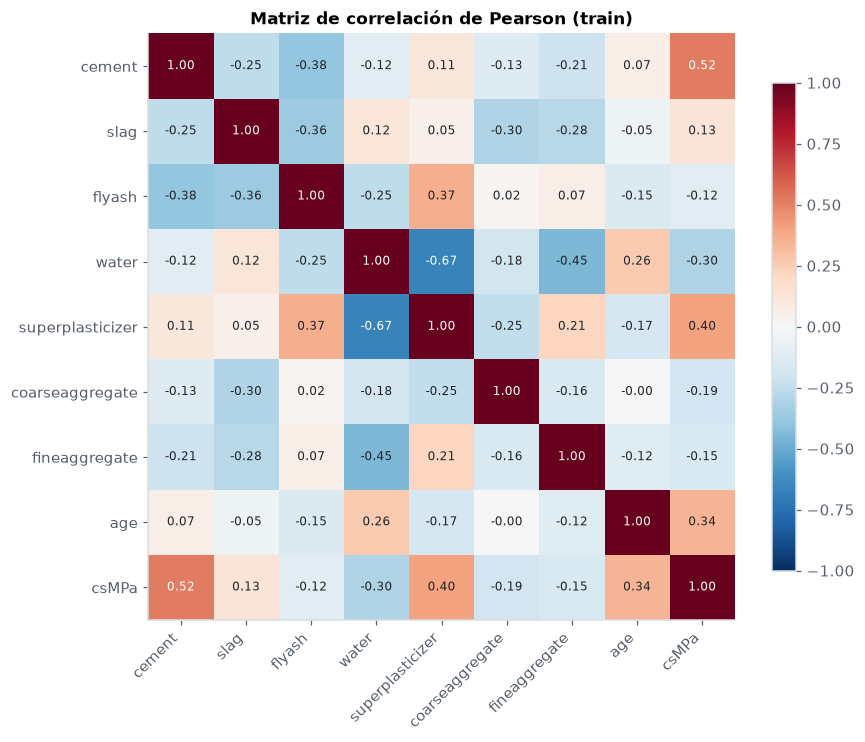

Correlación de cada predictor con csMPa:


,Pearson,Spearman,|Spearman| − |Pearson|
age,0.3410,0.6110,0.2700
cement,0.5200,0.5050,-0.0140
superplasticizer,0.4000,0.3780,-0.0210
water,-0.2990,-0.3250,0.0260
coarseaggregate,-0.1910,-0.2070,0.0150
fineaggregate,-0.1500,-0.1740,0.0240
slag,0.1320,0.1600,0.0270
flyash,-0.1150,-0.0850,-0.0300


Pares de predictores con |r| ≥ 0.35:
   water ~ superplasticizer: -0.669
   water ~ fineaggregate: -0.453
   cement ~ flyash: -0.384
   flyash ~ superplasticizer: +0.365
   slag ~ flyash: -0.362


In [11]:
corr = train_raw[NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(8.6, 7.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERICAS))); ax.set_xticklabels(NUMERICAS, rotation=45, ha="right")
ax.set_yticks(range(len(NUMERICAS))); ax.set_yticklabels(NUMERICAS)
for i in range(len(NUMERICAS)):
    for j in range(len(NUMERICAS)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.5 else TINTA)
ax.grid(False); ax.set_title("Matriz de correlación de Pearson (train)")
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

corr_obj = pd.DataFrame({
    "Pearson": train_raw[PREDICTORES].corrwith(train_raw[TARGET]),
    "Spearman": train_raw[PREDICTORES].corrwith(train_raw[TARGET], method="spearman"),
})
corr_obj["|Spearman| − |Pearson|"] = corr_obj["Spearman"].abs() - corr_obj["Pearson"].abs()
print("Correlación de cada predictor con csMPa:")
display(corr_obj.sort_values("Spearman", key=np.abs, ascending=False).round(3))

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(PREDICTORES) for b in PREDICTORES[i + 1:]
         if abs(corr.loc[a, b]) >= 0.35]
print("Pares de predictores con |r| ≥ 0.35:")
for a, b, r in sorted(pares, key=lambda t: -abs(t[2])):
    print(f"   {a} ~ {b}: {r:+.3f}")

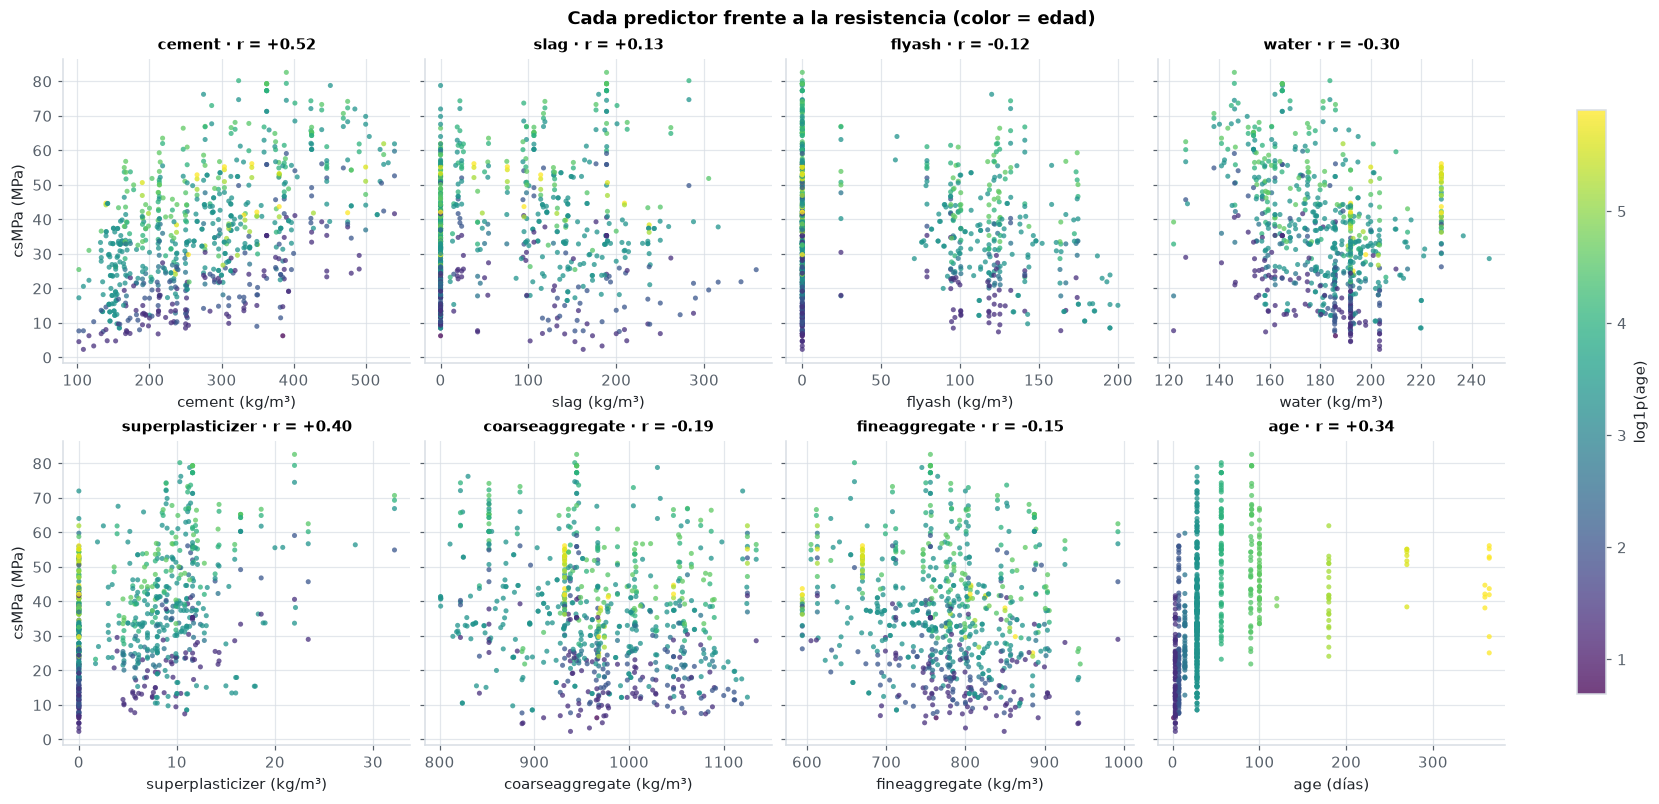

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharey=True, constrained_layout=True)
for ax, col in zip(axes.ravel(), PREDICTORES):
    sc = ax.scatter(train_raw[col], train_raw[TARGET], c=np.log1p(train_raw["age"]), cmap="viridis",
                    s=11, alpha=0.75, linewidths=0)
    ax.set_title(f"{col} · r = {corr.loc[col, TARGET]:+.2f}", fontsize=10)
    ax.set_xlabel(etiqueta(col))
for ax in axes[:, 0]:
    ax.set_ylabel(etiqueta(TARGET))
fig.colorbar(sc, ax=axes, shrink=0.85, label="log1p(age)")
fig.suptitle("Cada predictor frente a la resistencia (color = edad)", fontweight="bold")
plt.show()

**Interpretación.**

- **Ningún predictor explica por sí solo la resistencia.** El más asociado linealmente es `cement`
  (r ≈ +0.52), seguido de `superplasticizer` (≈ +0.40) y `age` (≈ +0.34); `water` es negativa (≈ −0.30), en la
  dirección que predice la ley de Abrams. Las nubes de puntos son anchas: la resistencia depende de
  **combinaciones** de componentes, que es el argumento para un modelo no lineal multivariado.
- **`age` es el caso más claro de relación monótona no lineal:** su Spearman (≈ 0.61) casi duplica su Pearson
  (≈ 0.34). En el gráfico se ve por qué: la resistencia sube rápido en las primeras semanas y luego se aplana.
  Además, el color revela que para un mismo contenido de cemento las probetas jóvenes (morado) quedan
  sistemáticamente abajo: **la edad modula el efecto de todos los componentes**.
- **Colinealidad:** `water` y `superplasticizer` tienen r ≈ −0.67 (el superplastificante permite reducir agua
  manteniendo la trabajabilidad) y `water`–`fineaggregate` r ≈ −0.45. No es un problema para la predicción de
  una MLP, pero sí advierte que los efectos individuales no deben leerse como causales: una correlación entre
  `superplasticizer` y resistencia puede reflejar, en parte, el menor contenido de agua que lo acompaña.

### 2.8 Relaciones de dominio: edad, agua/material cementante y presencia de componentes

Para evaluar las hipótesis de dominio se definen aquí las **variables derivadas candidatas**. La función
`construir_features` es la **única definición** de estas transformaciones en todo el notebook: el EDA la usa para
explorar y el preprocesamiento (sección 4) la reutiliza, de modo que train, validación y test se transforman
exactamente igual. Es **determinista** —no aprende ningún parámetro de los datos—, así que aplicarla a cualquier
partición no puede introducir fuga de información.

| Variable | Definición | Motivación |
|---|---|---|
| `log1p_age` | log(1 + age) | Comprimir la asimetría de la edad y reflejar la ganancia de resistencia decreciente |
| `cementante_total` | cement + slag + flyash | Masa total de material con capacidad cementante |
| `agua_cementante` | water / cementante_total | Versión de la relación de Abrams que incluye las adiciones |
| `agua_cemento` | water / cement | Relación agua/cemento clásica (ley de Abrams) |
| `tiene_slag`, `tiene_flyash`, `tiene_superplast` | 1 si el componente es > 0 | Capturar el "quiebre" de los ceros estructurales |

Las divisiones son seguras: la función **verifica** que `cement` > 0 en todas las filas (lo que garantiza
`cementante_total` > 0) y que el resultado sea finito; si un dato nuevo violara esos supuestos, falla con un error
explícito en lugar de producir infinitos silenciosos.

In [13]:
_SIN_EDAD = [c for c in PREDICTORES if c != "age"]
_DERIVADAS = ["log1p_age", "cementante_total", "agua_cementante", "agua_cemento"]
_INDICADORES = ["tiene_slag", "tiene_flyash", "tiene_superplast"]
CONJUNTOS_FEATURES = {
    "originales": PREDICTORES,                                     # 8 variables tal como vienen
    "log_edad": _SIN_EDAD + ["log1p_age"],                         # age reemplazada por log1p(age)
    "derivadas": _SIN_EDAD + _DERIVADAS,                           # + cementante total y relaciones de agua
    "derivadas_indicadores": _SIN_EDAD + _DERIVADAS + _INDICADORES,  # + indicadores de presencia
}


def construir_features(X, conjunto="originales"):
    """Devuelve el conjunto de variables pedido a partir de las 8 columnas originales.

    Determinista (no aprende parámetros): puede aplicarse a cualquier partición sin fuga de información.
    """
    if conjunto not in CONJUNTOS_FEATURES:
        raise ValueError(f"Conjunto desconocido: {conjunto}")
    faltantes = [c for c in PREDICTORES if c not in X.columns]
    if faltantes:
        raise KeyError(f"Faltan columnas predictoras: {faltantes}")
    base = X[PREDICTORES].astype("float64")
    if (base[COMPONENTES] < 0).any().any() or (base["age"] < 0).any():
        raise ValueError("Hay cantidades o edades negativas: las transformaciones no están definidas")
    if (base["cement"] <= 0).any():
        raise ValueError("cement <= 0: la relación agua/cemento no estaría definida")

    out = base.copy()
    out["log1p_age"] = np.log1p(base["age"])
    out["cementante_total"] = base["cement"] + base["slag"] + base["flyash"]
    out["agua_cementante"] = base["water"] / out["cementante_total"]
    out["agua_cemento"] = base["water"] / base["cement"]
    out["tiene_slag"] = (base["slag"] > 0).astype("float64")
    out["tiene_flyash"] = (base["flyash"] > 0).astype("float64")
    out["tiene_superplast"] = (base["superplasticizer"] > 0).astype("float64")

    out = out[CONJUNTOS_FEATURES[conjunto]]
    if not np.isfinite(out.to_numpy()).all():
        raise ValueError("La transformación produjo valores no finitos")
    assert TARGET not in out.columns and ID_COL not in out.columns
    return out


feats_eda = construir_features(train_raw, "derivadas_indicadores")
comparacion = pd.concat([train_raw[["age", "cement", "water"]], feats_eda[_DERIVADAS]], axis=1)
tabla_deriv = pd.DataFrame({
    "Pearson": comparacion.corrwith(train_raw[TARGET]),
    "Spearman": comparacion.corrwith(train_raw[TARGET], method="spearman"),
    "asimetría": comparacion.skew(),
    "mínimo": comparacion.min(), "máximo": comparacion.max(),
})
print("Variables derivadas frente a sus variables de origen (correlación con csMPa):")
display(tabla_deriv.round(3))

filas = []
for comp, ind in [("slag", "tiene_slag"), ("flyash", "tiene_flyash"), ("superplasticizer", "tiene_superplast")]:
    con = feats_eda[ind] == 1
    filas.append({"componente": comp, "n con": int(con.sum()), "csMPa medio con": y_raw[con].mean(),
                  "n sin": int((~con).sum()), "csMPa medio sin": y_raw[~con].mean(),
                  "diferencia (con − sin)": y_raw[con].mean() - y_raw[~con].mean()})
print("Resistencia media según presencia del componente:")
display(pd.DataFrame(filas).set_index("componente").round(2))

print("Resistencia por edad de ensayo:")
display(train_raw.groupby("age")[TARGET].agg(n="size", media="mean", desv="std").round(2).T)

Variables derivadas frente a sus variables de origen (correlación con csMPa):


,Pearson,Spearman,asimetría,mínimo,máximo
age,0.3410,0.6110,3.2760,1.0000,365.0000
cement,0.5200,0.5050,0.4430,102.0000,540.0000
water,-0.2990,-0.3250,0.0700,121.8000,247.0000
log1p_age,0.5640,0.6110,-0.0480,0.6930,5.9030
cementante_total,0.6220,0.6040,0.3590,200.0000,640.0000
agua_cementante,-0.6270,-0.6100,0.3620,0.2350,0.9000
agua_cemento,-0.5280,-0.5470,0.9850,0.2670,1.8820


Resistencia media según presencia del componente:


,n con,csMPa medio con,n sin,csMPa medio sin,diferencia (con − sin)
componente,,,,,
slag,399,39.9800,322,31.4300,8.5500
flyash,334,34.9100,387,37.2500,-2.3400
superplasticizer,472,39.8700,249,29.1400,10.7200


Resistencia por edad de ensayo:


age,1,3,7,14,28,56,90,91,100,120,180,270,360,365
n,1.0000,96.0000,82.0000,45.0000,298.0000,69.0000,27.0000,19.0000,41.0000,2.0000,22.0000,7.0000,4.0000,8.0000
media,6.2700,18.8300,25.5000,28.5300,36.7000,53.2100,41.0800,69.7000,48.2000,39.7800,41.1000,51.2400,41.5400,44.6700
desv,NaN,9.9200,14.7700,8.7500,14.6900,15.2900,9.8600,7.6400,8.9500,1.5300,9.4500,5.9100,2.7200,11.8700


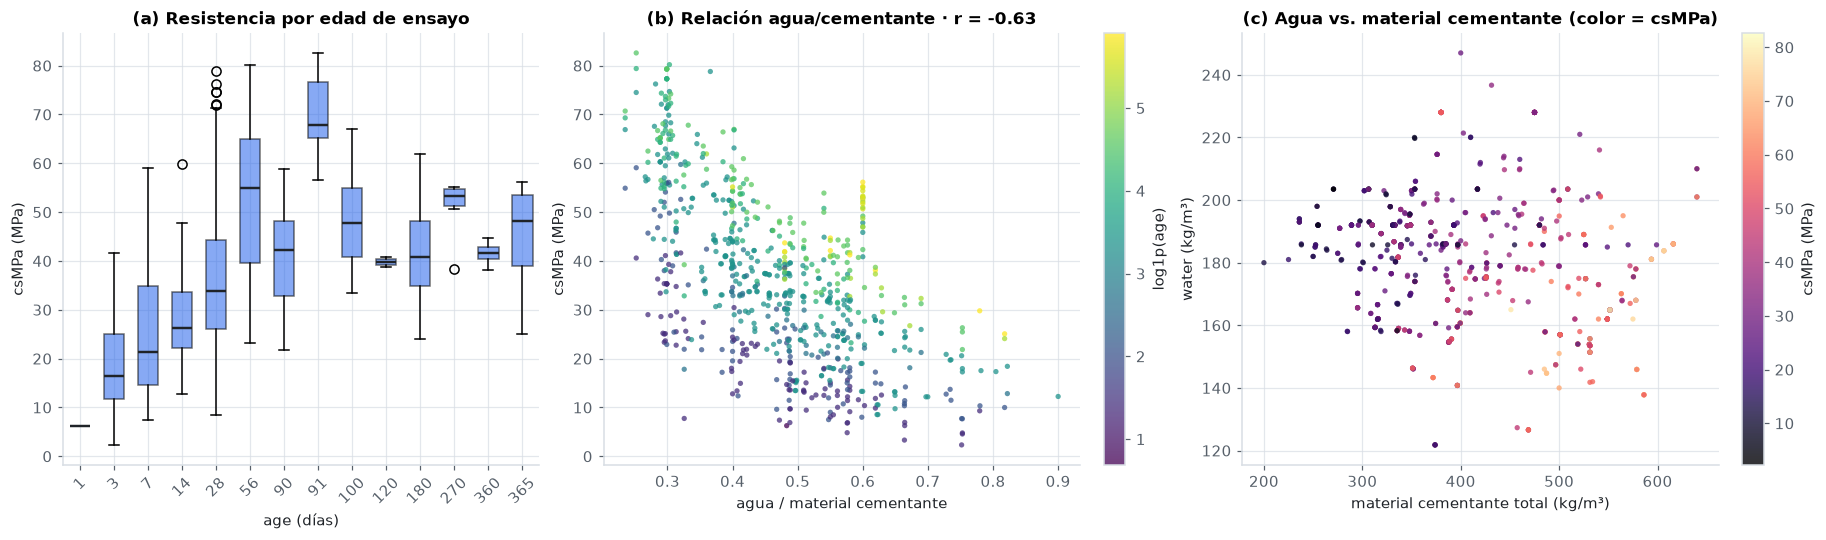

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), constrained_layout=True)

edades_unicas = sorted(train_raw["age"].unique())
datos_edad = [train_raw.loc[train_raw["age"] == a, TARGET].to_numpy() for a in edades_unicas]
axes[0].boxplot(datos_edad, positions=range(len(edades_unicas)), widths=0.6, patch_artist=True,
                boxprops=dict(facecolor=PALETA[0], alpha=0.55), medianprops=dict(color=TINTA, lw=1.6))
axes[0].set_xticks(range(len(edades_unicas)))
axes[0].set_xticklabels([str(int(a)) for a in edades_unicas], rotation=45)
axes[0].set_xlabel("age (días)"); axes[0].set_ylabel(etiqueta(TARGET))
axes[0].set_title("(a) Resistencia por edad de ensayo")

sc = axes[1].scatter(feats_eda["agua_cementante"], train_raw[TARGET], c=feats_eda["log1p_age"],
                     cmap="viridis", s=12, alpha=0.75, linewidths=0)
axes[1].set_xlabel("agua / material cementante"); axes[1].set_ylabel(etiqueta(TARGET))
axes[1].set_title(f"(b) Relación agua/cementante · r = {tabla_deriv.loc['agua_cementante', 'Pearson']:+.2f}")
fig.colorbar(sc, ax=axes[1], label="log1p(age)")

sc2 = axes[2].scatter(feats_eda["cementante_total"], train_raw["water"], c=train_raw[TARGET],
                      cmap="magma", s=12, alpha=0.8, linewidths=0)
axes[2].set_xlabel("material cementante total (kg/m³)"); axes[2].set_ylabel(etiqueta("water"))
axes[2].set_title("(c) Agua vs. material cementante (color = csMPa)")
fig.colorbar(sc2, ax=axes[2], label="csMPa (MPa)")
plt.show()

**Interpretación.**

- **(a) Edad.** La resistencia media pasa de ≈ 18.8 MPa a 3 días a ≈ 25.5 a 7 días y ≈ 36.7 a 28 días: crecimiento
  rápido y luego más lento, compatible con la hipótesis de hidratación. **Pero la curva no es monótona** a edades
  altas (p. ej. ≈ 41.1 MPa a 90 días frente a ≈ 69.7 a 91 días): cada edad la ensayaron mezclas distintas, así que
  la media por edad mezcla el efecto de la edad con el de la dosificación. Es una advertencia contra leer
  relaciones marginales como causales. `log1p(age)` reduce la asimetría de ≈ 3.3 a ≈ 0 y sube la correlación
  lineal de ≈ 0.34 a ≈ 0.56 (Spearman no cambia, porque la transformación conserva el orden).
- **(b) Agua/material cementante.** Con r ≈ −0.63 es la variable con **mayor correlación lineal absoluta** de
  todas, por encima de cualquier original y de la relación agua/cemento clásica (≈ −0.53); el material
  cementante total (≈ +0.62) también supera a `cement` sola (≈ +0.52). Dentro de cada color (edad) la pendiente
  negativa es nítida: la ley de Abrams se observa en los datos.
- **(c) Agua vs. cementante.** No es la cantidad de agua por sí sola, sino su **proporción** respecto al material
  cementante lo que se asocia con la resistencia: los puntos claros (alta resistencia) se concentran donde hay
  mucho cementante para una cantidad de agua dada.
- **Presencia de componentes:** las mezclas con escoria tienen ≈ 8.6 MPa más de media que las que no la usan, y
  con superplastificante ≈ 10.7 MPa más; con ceniza volante ≈ 2.3 MPa **menos**. Son diferencias marginales,
  confundidas con el resto de la dosificación.

**Hipótesis que se derivan (no conclusiones):** estas correlaciones univariadas sugieren que `log1p(age)` y las
relaciones agua/cementante podrían facilitarle el aprendizaje a la red con sólo ~700 observaciones. **No prueban
que mejoren la MLP**, porque una red no lineal podría construir esas combinaciones por sí sola; por eso se
comparan experimentalmente en la sección 8.

### 2.9 ¿Se parecen las distribuciones de train y test?

Si test proviniera de una población distinta, la validación interna dejaría de ser una buena estimación del
puntaje de Kaggle. Se comparan las distribuciones de cada predictor con histogramas superpuestos y con la prueba de
Kolmogorov–Smirnov de dos muestras (con valores repetidos el p-valor es aproximado; se usa como indicador, no como
veredicto). Además, como el dataset contiene la **misma mezcla ensayada a varias edades**, se mide cuántas filas de
test usan una mezcla que también aparece en train: eso determina cómo debe construirse la validación.

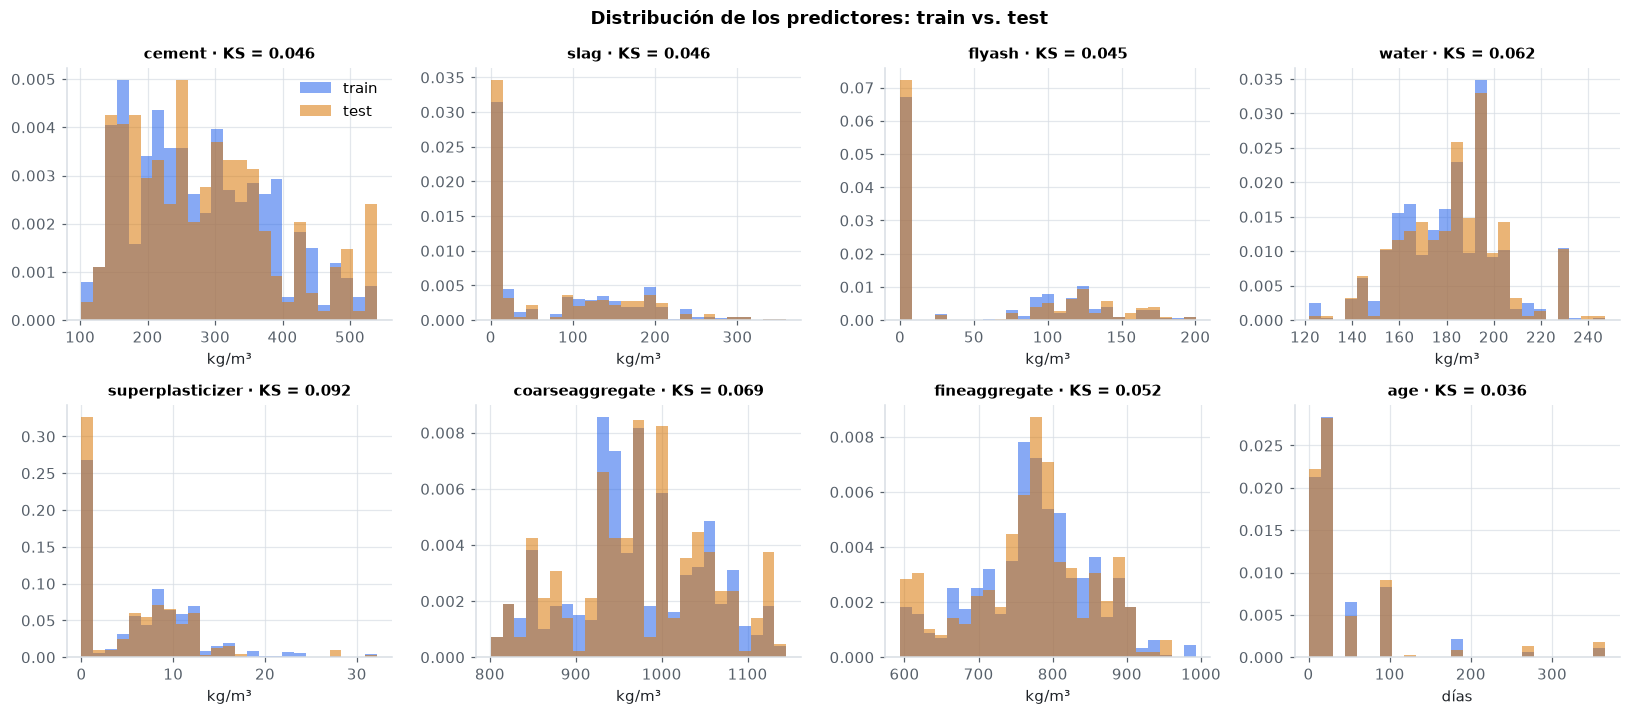

,media train,media test,% ceros train,% ceros test,KS,p-valor (aprox.),fuera del rango de train (test)
variable,,,,,,,
cement,280.6300,282.4240,0.0000,0.0000,0.0460,0.7390,0
slag,74.7360,71.9350,44.6600,48.2200,0.0460,0.7270,0
flyash,54.8740,52.5880,53.6750,57.9290,0.0450,0.7610,1
water,181.0300,182.8210,0.0000,0.0000,0.0620,0.3550,0
superplasticizer,6.5030,5.5080,34.5350,42.0710,0.0920,0.0480,0
coarseaggregate,971.4020,976.4590,0.0000,0.0000,0.0690,0.2460,1
fineaggregate,775.1260,769.9750,0.0000,0.0000,0.0520,0.5900,0
age,44.9510,47.3200,0.0000,0.0000,0.0360,0.9320,0


Mezclas distintas en train: 343 (ensayadas a más de una edad: 147)
Filas de test cuya mezcla (7 componentes) aparece en train: 216 de 309 (69.9 %)


In [15]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
filas_ks = []
for ax, col in zip(axes.ravel(), PREDICTORES):
    bordes = np.histogram_bin_edges(pd.concat([train_raw[col], test_raw[col]]), bins=25)
    ax.hist(train_raw[col], bins=bordes, density=True, alpha=0.55, color=PALETA[0], label="train")
    ax.hist(test_raw[col], bins=bordes, density=True, alpha=0.55, color=PALETA[1], label="test")
    ks = stats.ks_2samp(train_raw[col], test_raw[col])
    ax.set_title(f"{col} · KS = {ks.statistic:.3f}", fontsize=10); ax.set_xlabel(UNIDADES[col])
    filas_ks.append({"variable": col, "media train": train_raw[col].mean(), "media test": test_raw[col].mean(),
                     "% ceros train": 100 * (train_raw[col] == 0).mean(), "% ceros test": 100 * (test_raw[col] == 0).mean(),
                     "KS": ks.statistic, "p-valor (aprox.)": ks.pvalue,
                     "fuera del rango de train (test)": int(((test_raw[col] < train_raw[col].min()) |
                                                             (test_raw[col] > train_raw[col].max())).sum())})
axes[0, 0].legend()
fig.suptitle("Distribución de los predictores: train vs. test", fontweight="bold")
fig.tight_layout(); plt.show()
display(pd.DataFrame(filas_ks).set_index("variable").round(3))

mezclas_por_fila = train_raw.groupby(COMPONENTES).size()
mezclas_train = set(mezclas_por_fila.index)
comparte_mezcla = np.array([tuple(f) in mezclas_train for f in test_raw[COMPONENTES].to_numpy()])
print(f"Mezclas distintas en train: {len(mezclas_train)} (ensayadas a más de una edad: {int((mezclas_por_fila > 1).sum())})")
print(f"Filas de test cuya mezcla (7 componentes) aparece en train: {int(comparte_mezcla.sum())} de {len(test_raw)} "
      f"({100 * comparte_mezcla.mean():.1f} %)")

**Interpretación.** Las distribuciones de train y test son muy parecidas: todos los estadísticos KS son pequeños
y sólo dos valores de test quedan apenas fuera del rango de train. La diferencia más visible está en
`superplasticizer` (KS ≈ 0.09, en el límite de la significación convencional): test tiene una proporción algo
mayor de mezclas sin superplastificante (≈ 42 % frente a ≈ 35 %). Es una diferencia leve que no justifica
ninguna corrección, pero que se deja registrada como posible fuente de discrepancia entre la validación y Kaggle.

El dato más útil para el diseño es el último: **≈ 70 % de las filas de test usan una mezcla que también está en
train** (ensayada a otra edad). Es decir, Kaggle separó train y test **por filas, al azar**, no por mezclas. Por
eso la validación interna también será **aleatoria por filas** (`KFold` con `shuffle=True`): reproduce la relación
real entre train y test. Una validación agrupada por mezcla mediría otra cosa —generalizar a mezclas nunca vistas—
y sería más pesimista que el leaderboard.

### 2.10 Hallazgos que guían el preprocesamiento

1. **Todas las variables son numéricas, completas y en escalas muy distintas** (≈ 0–32 kg/m³ frente a ≈ 800–1 134
   kg/m³). ⇒ No se requiere encoding ni imputación; el **escalamiento de los predictores es indispensable** para la
   red (sección 4).
2. **`age` es discreta, muy asimétrica (≈ 3.3) y tiene una relación monótona no lineal con la resistencia**
   (Spearman ≈ 0.61 frente a Pearson ≈ 0.34). ⇒ Se evaluará `log1p(age)` como primera decisión de representación
   (experimento E1).
3. **La proporción agua/material cementante es la variable más asociada linealmente con la resistencia**
   (r ≈ −0.63), por encima de cualquier variable original, y tres componentes tienen ceros estructurales
   (≈ 35–54 %). ⇒ Se evaluarán variables derivadas (E2) e indicadores de presencia (E3), **sin asumir** que
   mejoren una red no lineal.
4. **Hay 16 copias exactas y 7 grupos de réplicas con resistencias distintas.** ⇒ Se eliminan sólo las copias
   exactas, antes de partir los datos (sección 3); las réplicas se conservan y se interpretan como ruido
   experimental, es decir, como un piso de error alcanzable.
5. **Train y test son comparables, y ≈ 70 % de las filas de test comparten mezcla con train.** ⇒ La validación
   cruzada se hace aleatoria por filas, igual que la partición de Kaggle.

---
# 3. Limpieza: tratamiento de duplicados

**Criterio acordado:** eliminar **únicamente** las filas idénticas en los 8 predictores **y** en `csMPa`
(ignorando `Row ID`), conservando la primera aparición. Las filas que comparten predictores pero tienen distinta
resistencia **se conservan**.

**Justificación.**

- **Por qué eliminar las copias exactas, y antes de partir.** Si una copia queda en entrenamiento y la otra en
  validación, el modelo "acierta" esa fila por memoria y la métrica de validación se infla. Con ~700 filas, 16
  copias (≈ 2 %) no son despreciables. Es el mismo argumento con el que el Taller 1 eliminó los duplicados de
  Thyroid. Eliminar duplicados exactos es una **regla fija**, que no estima ningún parámetro con los datos, así que
  aplicarla antes de la partición no introduce fuga.
- **Por qué conservar las réplicas con distinta resistencia.** Son mediciones legítimas de la variabilidad del
  ensayo. Eliminarlas daría un problema artificialmente "limpio" y una estimación optimista del error. No hay
  evidencia de que alguna sea un error de captura, así que no se descarta ninguna.
- **Limitación de la decisión.** Sin un identificador de probeta no puede saberse si una copia exacta es un
  registro cargado dos veces o **dos ensayos reales que dieron la misma lectura**. Si fuera lo segundo, eliminarla
  le quita algo de peso a esa mezcla y reduce ligeramente la variabilidad observada; con 16 de 721 filas, el efecto
  sobre la distribución es pequeño, y la celda siguiente lo cuantifica comparando el objetivo antes y después.
- **Efecto sobre la representatividad.** Test podría contener copias de filas de train (la sección 2.3 encontró 11
  filas de test cuyo vector de predictores aparece en train). Para esas filas, el puntaje de Kaggle puede ser algo
  mejor que nuestra validación; es una diferencia esperable y se tiene en cuenta al comparar ambos números.

In [16]:
n_antes = len(train_raw)
df_limpio = train_raw.drop_duplicates(subset=PREDICTORES + [TARGET], keep="first").reset_index(drop=True)
n_eliminadas = n_antes - len(df_limpio)

print(f"Filas antes: {n_antes} · eliminadas: {n_eliminadas} · después: {len(df_limpio)}  → df_limpio {df_limpio.shape}")
if n_eliminadas != 16:
    print("⚠️  El número de copias exactas difiere del diagnóstico preliminar (16): revisar el archivo.")

assert not df_limpio.duplicated(subset=PREDICTORES + [TARGET]).any()
conflictivos_despues = df_limpio.groupby(PREDICTORES)[TARGET].nunique()
assert int((conflictivos_despues > 1).sum()) == len(conflictivos), "Se perdió algún grupo de réplicas"
print(f"Grupos de réplicas con resistencia distinta conservados: {int((conflictivos_despues > 1).sum())}")

display(pd.DataFrame({"antes de limpiar": train_raw[TARGET].describe(),
                      "después de limpiar": df_limpio[TARGET].describe()}).T.round(2))

Filas antes: 721 · eliminadas: 16 · después: 705  → df_limpio (705, 10)
Grupos de réplicas con resistencia distinta conservados: 7


,count,mean,std,min,25%,50%,75%,max
antes de limpiar,721.0000,36.1600,17.2000,2.3300,23.3500,34.5700,47.7100,82.6000
después de limpiar,705.0000,35.5400,16.7200,2.3300,23.0800,33.7600,46.3900,82.6000


**Resultado.** La tabla compara el objetivo antes y después de eliminar las copias exactas. El cambio no es nulo:
la media baja de ≈ 36.16 a ≈ 35.54 MPa y la mediana de ≈ 34.57 a ≈ 33.76 MPa, porque las copias eliminadas
correspondían en promedio a mezclas de resistencia alta. Es un desplazamiento pequeño (≈ 0.04 desviaciones
estándar) que deja intactos el mínimo y el máximo, pero confirma la limitación señalada arriba: si esas copias
eran ensayos repetidos legítimos, la limpieza reduce ligeramente el peso de ese tipo de mezclas. Se acepta este
costo porque, a cambio, ninguna copia exacta puede aparecer a ambos lados de una partición.

---
# 4. Preprocesamiento y estrategia de evaluación (Parte 2)

### 4.1 Estrategia de evaluación: qué conjunto cumple qué función

| Conjunto | Construcción | Para qué se usa | Para qué **no** se usa |
|---|---|---|---|
| **Split 80/20** (`df_train` / `df_valid`) | `train_test_split(random_state=42)` sobre `df_limpio` | Parte 5: entrenar el modelo base, early stopping, curvas y métricas train vs. validación | Seleccionar configuraciones |
| **K-Fold (K = 5)** sobre `df_limpio` | `KFold(shuffle=True, random_state=42)`; dentro de cada fold, 15 % del fold-train para early stopping | Parte 6: comparar *baselines* y experimentos, y **seleccionar** el modelo | — |
| **`test.csv`** | Archivo de Kaggle, sin objetivo | Sólo predicción final | Elegir arquitectura, hiperparámetros, época o modelo |

**Por qué dos esquemas.** El enunciado pide una partición entrenamiento/validación y curvas de aprendizaje (Parte 5),
y recomienda K-Fold para comparar experimentos (Parte 6). Con sólo ~141 filas de validación, el MSE de un único
split depende bastante de qué filas caigan en él; el K-Fold usa cada fila exactamente una vez como validación y
entrega media ± desviación, que es lo que permite decidir si una diferencia es real o ruido. Por eso **todas las
decisiones de selección se toman con K-Fold**, y el split 80/20 se usa sólo para la demostración y el diagnóstico
del entrenamiento.

**Early stopping sin contaminar la validación.** En el split 80/20 la época de parada se elige con `df_valid`, como
indica el enunciado; por eso las métricas de validación de la Parte 5 son **ligeramente optimistas** (ese mismo
conjunto eligió la época). En el K-Fold se evita ese sesgo: la época se elige con un 15 % interno del fold de
entrenamiento, y el fold de validación **sólo mide**. El costo es que la red entrena con ~85 % del fold de
entrenamiento; para que la comparación sea justa, los *baselines* se ajustan con esas mismas filas.

### 4.2 Valores faltantes, encoding y la opción de tratar `age` como categórica

- **Faltantes:** la sección 1.2 verificó 0 faltantes e infinitos en train y test ⇒ **no se imputa**. No se añade un
  `SimpleImputer` "por si acaso": los datos de test tampoco tienen faltantes, y la verificación de valores finitos
  antes de crear tensores (sección 4.3) hace que un dato faltante futuro falle de forma explícita en vez de
  rellenarse sin que nadie lo note.
- **Encoding:** **no hay variables categóricas** (sección 2.4) ⇒ no se requiere One-Hot, ordinal ni ningún otro
  encoding.
- **`age` como categórica (opción del enunciado): no se adopta.** Sus 14 valores **sí tienen orden y distancia con
  significado** (28 días está más cerca de 56 que de 365), y la resistencia crece con ellos. Un One-Hot descartaría
  ese orden y crearía columnas casi vacías (hay edades con 1 o 2 filas, como 1 y 120 días). `log1p(age)` conserva el
  orden y reduce la asimetría, así que es la alternativa que se evalúa. Como no se adopta el enfoque categórico, no
  hay dos enfoques que comparar.

### 4.3 Escalamiento: decisión y justificación

| Técnica | Qué usa | Decisión para este dataset |
|---|---|---|
| `MinMaxScaler` | mínimo y máximo | **No.** Lo fijan las dos observaciones más extremas; en `slag`, `flyash` y `superplasticizer`, con ceros estructurales y colas, comprimiría la mayoría de las mezclas en una franja estrecha. |
| **`StandardScaler`** | media y desviación | **Sí, para predictores y objetivo.** La sección 2 no encontró valores imposibles ni colas extremas en los componentes, y la variable más asimétrica (`age`) se trata con `log1p` en los experimentos. Deja todas las entradas en O(1), lo que favorece una optimización estable con Adam y la inicialización por defecto de PyTorch. |
| `RobustScaler` | mediana e IQR | **No necesario.** En el Taller 1 se eligió por la cola de tarifas de Uber; aquí no hay una cola comparable. Además, en variables con > 50 % de ceros, como `flyash`, la mediana es 0. |

Las transformaciones que aprenden parámetros (`StandardScaler` de X y de y) se encapsulan en funciones que **sólo
reciben el subconjunto de entrenamiento** de cada partición; validación y test sólo pasan por `.transform()`. El
cálculo de variables derivadas va dentro del mismo `Pipeline` de scikit-learn, de modo que es imposible escalar
algo sin haberlo construido de la misma forma.

In [17]:
def nuevo_preprocesador(conjunto):
    """Pipeline: variables derivadas (deterministas) → StandardScaler (aprende sólo en fit)."""
    return Pipeline([
        ("features", FunctionTransformer(construir_features, kw_args={"conjunto": conjunto})),
        ("escalador", StandardScaler()),
    ])


def ajustar_transformaciones(df_fit, conjunto):
    """Ajusta el preprocesador de X y el escalador de y EXCLUSIVAMENTE con df_fit."""
    prep = nuevo_preprocesador(conjunto).fit(df_fit[PREDICTORES])
    esc_y = StandardScaler().fit(df_fit[[TARGET]].to_numpy(dtype=np.float64))
    return prep, esc_y


def transformar_X(prep, df):
    X = prep.transform(df[PREDICTORES]).astype(np.float32)
    assert X.ndim == 2 and np.isfinite(X).all(), "X transformada con valores no finitos"
    return X


def transformar_y(esc_y, df):
    y = esc_y.transform(df[[TARGET]].to_numpy(dtype=np.float64)).astype(np.float32)
    assert y.shape == (len(df), 1) and np.isfinite(y).all()
    return y


def invertir_y(esc_y, y_escalada):
    """Vuelve de la escala estandarizada a MPa. Devuelve un vector 1-D."""
    return esc_y.inverse_transform(np.asarray(y_escalada, dtype=np.float64).reshape(-1, 1)).ravel()


# Validez de todas las transformaciones sobre train y test (sin ajustar nada: sólo construir variables)
for nombre in CONJUNTOS_FEATURES:
    f_tr, f_te = construir_features(df_limpio, nombre), construir_features(test_raw, nombre)
    assert list(f_tr.columns) == list(f_te.columns)
    print(f"{nombre:<23} → {f_tr.shape[1]:>2} variables · train {f_tr.shape} · test {f_te.shape} · todo finito ✔")

originales              →  8 variables · train (705, 8) · test (309, 8) · todo finito ✔
log_edad                →  8 variables · train (705, 8) · test (309, 8) · todo finito ✔
derivadas               → 11 variables · train (705, 11) · test (309, 11) · todo finito ✔
derivadas_indicadores   → 14 variables · train (705, 14) · test (309, 14) · todo finito ✔


### 4.4 Partición 80/20 reproducible

In [18]:
df_train, df_valid = train_test_split(df_limpio, test_size=0.20, random_state=SEED, shuffle=True)
assert set(df_train.index).isdisjoint(df_valid.index) and len(df_train) + len(df_valid) == len(df_limpio)

pd.DataFrame({
    "filas": [len(df_train), len(df_valid), len(df_limpio)],
    "% del total": [100 * len(df_train) / len(df_limpio), 100 * len(df_valid) / len(df_limpio), 100.0],
    "csMPa media": [df_train[TARGET].mean(), df_valid[TARGET].mean(), df_limpio[TARGET].mean()],
    "csMPa desv.": [df_train[TARGET].std(), df_valid[TARGET].std(), df_limpio[TARGET].std()],
}, index=["Entrenamiento (df_train)", "Validación (df_valid)", "Total (df_limpio)"]).round(2)

,filas,% del total,csMPa media,csMPa desv.
Entrenamiento (df_train),564,80.0000,35.3600,16.5200
Validación (df_valid),141,20.0000,36.2500,17.5300
Total (df_limpio),705,100.0000,35.5400,16.7200


### 4.5 Verificación explícita de ausencia de *data leakage*

**Afirmación:** los escaladores aprenden sólo de `df_train`. **Comprobación empírica:** si eso es cierto, la media y
la desviación aprendidas deben coincidir exactamente con las calculadas a mano sobre `df_train` y **diferir** de las
del dataset completo; además, transformar validación y test no debe modificar ningún parámetro aprendido. Se usa
el conjunto de variables más rico (`derivadas`) para que la comprobación cubra también las variables construidas.

In [19]:
prep_demo, esc_y_demo = ajustar_transformaciones(df_train, "derivadas")
esc_X = prep_demo.named_steps["escalador"]
f_train = construir_features(df_train, "derivadas")
f_total = construir_features(df_limpio, "derivadas")

verif = pd.DataFrame({
    "media aprendida": esc_X.mean_,
    "media en df_train": f_train.mean().to_numpy(),
    "media en df_limpio completo": f_total.mean().to_numpy(),
    "desv. aprendida": esc_X.scale_,
    "desv. en df_train (ddof=0)": f_train.std(ddof=0).to_numpy(),
}, index=f_train.columns)
display(verif.round(4))

coincide_train = np.allclose(esc_X.mean_, f_train.mean()) and np.allclose(esc_X.scale_, f_train.std(ddof=0))
coincide_total = np.allclose(esc_X.mean_, f_total.mean())
coincide_y = np.isclose(esc_y_demo.mean_[0], df_train[TARGET].mean())
print("¿El escalador de X aprendió EXACTAMENTE de df_train?       ", coincide_train)
print("¿Coincide con el dataset completo (señal de fuga)?          ", coincide_total)
print("¿El escalador de y aprendió la media de csMPa de df_train?  ", coincide_y)

media_antes = esc_X.mean_.copy()
X_valid_demo = transformar_X(prep_demo, df_valid)
_ = transformar_X(prep_demo, test_raw)
print("¿Transformar validación y test cambió los parámetros?       ", not np.array_equal(media_antes, esc_X.mean_))
print(f"Media de las variables transformadas — train: {transformar_X(prep_demo, df_train).mean():+.4f} · "
      f"validación: {X_valid_demo.mean():+.4f} (no tiene por qué ser 0: se escaló con los parámetros de train)")
assert coincide_train and coincide_y and not coincide_total and np.array_equal(media_antes, esc_X.mean_)
print("✅ Sin fuga: fit sólo sobre entrenamiento; validación y test sólo reciben transform.")

,media aprendida,media en df_train,media en df_limpio completo,desv. aprendida,desv. en df_train (ddof=0)
cement,277.0124,277.0124,278.3268,103.1467,103.1467
slag,74.8679,74.8679,72.7296,86.1665,86.1665
flyash,55.9940,55.9940,56.1194,63.6635,63.6635
water,181.9885,181.9885,181.4767,21.8363,21.8363
superplasticizer,6.2363,6.2363,6.3528,5.9290,5.9290
coarseaggregate,970.6284,970.6284,972.6644,75.5947,75.5947
fineaggregate,774.8995,774.8995,774.6332,81.4016,81.4016
log1p_age,3.2376,3.2376,3.2402,1.1149,1.1149
cementante_total,407.8743,407.8743,407.1759,90.9152,90.9152
agua_cementante,0.4703,0.4703,0.4704,0.1233,0.1233


¿El escalador de X aprendió EXACTAMENTE de df_train?        True
¿Coincide con el dataset completo (señal de fuga)?           False
¿El escalador de y aprendió la media de csMPa de df_train?   True
¿Transformar validación y test cambió los parámetros?        False
Media de las variables transformadas — train: +0.0000 · validación: -0.0067 (no tiene por qué ser 0: se escaló con los parámetros de train)
✅ Sin fuga: fit sólo sobre entrenamiento; validación y test sólo reciben transform.


**Conclusión de la verificación.** Los parámetros aprendidos reproducen los de `df_train` y no los del dataset
completo, y transformar validación y test no los altera. Las únicas operaciones aplicadas antes de partir los datos
(eliminar copias exactas y construir variables derivadas) son **reglas fijas** que no estiman nada a partir de los
datos. Durante el K-Fold (sección 8) se repite exactamente este procedimiento **desde cero en cada fold**: un
escalador nuevo por fold, ajustado sólo con las filas de entrenamiento de ese fold.

---
# 5. `Dataset` y `DataLoader` en PyTorch (Parte 3)

Se adapta `MyDataset` del notebook de clase `02_asl.ipynb` (material de referencia del curso, no incluido en este
repositorio) con los cambios que exige la regresión:

| Elemento | `MyDataset` (ASL, clasificación) | `ConcretoDataset` (este taller) |
|---|---|---|
| Tipo del objetivo | `long`, forma `(N,)` | **`float32`, forma `(N, 1)`** |
| Validaciones | ninguna | dimensiones, coincidencia de longitudes y valores finitos |
| Dispositivo | tensores en `device` desde `__init__` | igual (el dataset es pequeño y cabe entero en memoria/GPU) |

`train_loader` usa `shuffle=True` (un orden distinto en cada época, reproducible gracias a un generador con
semilla) y `valid_loader` usa `shuffle=False` (el orden no afecta a la evaluación y así es determinista).

In [20]:
class ConcretoDataset(Dataset):
    """Dataset tabular de regresión: X float32 (N, d) e y float32 (N, 1), ya en el dispositivo."""

    def __init__(self, X, y=None):
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError("X debe ser una matriz 2-D sin valores no finitos")
        self.xs = torch.tensor(X, dtype=torch.float32, device=device)
        self.ys = None
        if y is not None:
            y = np.asarray(y, dtype=np.float32).reshape(-1, 1)   # forma (N, 1): evita broadcasting en MSELoss
            if len(y) != len(X) or not np.isfinite(y).all():
                raise ValueError("y debe tener la misma longitud que X y valores finitos")
            self.ys = torch.tensor(y, dtype=torch.float32, device=device)

    def __getitem__(self, idx):
        if self.ys is None:
            return self.xs[idx]
        return self.xs[idx], self.ys[idx]

    def __len__(self):
        return len(self.xs)


def crear_loaders(X_fit, y_fit, X_val, y_val, batch_size, seed):
    generador = torch.Generator().manual_seed(seed)   # orden de batches reproducible
    train_loader = DataLoader(ConcretoDataset(X_fit, y_fit), batch_size=batch_size, shuffle=True, generator=generador)
    valid_loader = DataLoader(ConcretoDataset(X_val, y_val), batch_size=256, shuffle=False)
    return train_loader, valid_loader

In [21]:
# Demostración con las 8 variables originales y la partición 80/20
prep_base_demo, esc_y_base_demo = ajustar_transformaciones(df_train, "originales")
X_tr_demo, y_tr_demo = transformar_X(prep_base_demo, df_train), transformar_y(esc_y_base_demo, df_train)
X_va_demo, y_va_demo = transformar_X(prep_base_demo, df_valid), transformar_y(esc_y_base_demo, df_valid)
train_loader_demo, valid_loader_demo = crear_loaders(X_tr_demo, y_tr_demo, X_va_demo, y_va_demo, batch_size=32, seed=SEED)

x0, y0 = train_loader_demo.dataset[0]
xb, yb = next(iter(train_loader_demo))
print(f"len(train_dataset) = {len(train_loader_demo.dataset)} · len(valid_dataset) = {len(valid_loader_demo.dataset)}")
print(f"Un ejemplo: x {tuple(x0.shape)} {x0.dtype} en {x0.device} · y {tuple(y0.shape)} {y0.dtype}")
print(f"Un batch  : xb {tuple(xb.shape)} · yb {tuple(yb.shape)} · batches por época = {len(train_loader_demo)}")
print("Muestreador train:", type(train_loader_demo.sampler).__name__, "| valid:", type(valid_loader_demo.sampler).__name__)

assert xb.dtype == torch.float32 and yb.dtype == torch.float32
assert yb.ndim == 2 and yb.shape[1] == 1 and xb.shape[0] == yb.shape[0]
assert isinstance(train_loader_demo.sampler, RandomSampler) and isinstance(valid_loader_demo.sampler, SequentialSampler)
print("✅ float32, objetivo (N, 1), shuffle=True en train y shuffle=False en validación")

len(train_dataset) = 564 · len(valid_dataset) = 141
Un ejemplo: x (8,) torch.float32 en cpu · y (1,) torch.float32
Un batch  : xb (32, 8) · yb (32, 1) · batches por época = 18
Muestreador train: RandomSampler | valid: SequentialSampler
✅ float32, objetivo (N, 1), shuffle=True en train y shuffle=False en validación


**Por qué importa la forma `(N, 1)`.** La celda siguiente reproduce el error común que advierte el enunciado:
si las predicciones tienen forma `(N, 1)` y el objetivo `(N,)`, `MSELoss` hace *broadcasting* a una matriz
`(N, N)` y devuelve un valor que **no** es el MSE, aunque las predicciones sean perfectas.

In [22]:
pred_perfecta = torch.tensor([[1.0], [2.0], [3.0], [4.0]])     # (4, 1)
objetivo_mal = torch.tensor([1.0, 2.0, 3.0, 4.0])             # (4,)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)                # PyTorch avisa del broadcasting; aquí se muestra a propósito
    mse_mal = nn.MSELoss()(pred_perfecta, objetivo_mal).item()
mse_bien = nn.MSELoss()(pred_perfecta, objetivo_mal.view(-1, 1)).item()
print(f"MSE con objetivo (N,)  : {mse_mal:.3f}  ← incorrecto: broadcasting a (N, N)")
print(f"MSE con objetivo (N, 1): {mse_bien:.3f}  ← correcto: predicción perfecta ⇒ 0")

MSE con objetivo (N,)  : 2.500  ← incorrecto: broadcasting a (N, N)
MSE con objetivo (N, 1): 0.000  ← correcto: predicción perfecta ⇒ 0


---
# 6. Arquitectura de la MLP (Parte 4)

**Diseño.** Una MLP configurable `nn.Module` con:

- **≥ 3 capas ocultas** `nn.Linear` + activación (ReLU por defecto). La clase **rechaza** configuraciones con menos de
  tres capas ocultas.
- **Salida de 1 neurona sin activación**: la resistencia es un número real y cualquier activación final (sigmoide,
  ReLU, …) restringiría artificialmente el rango de la predicción.
- **Dropout opcional** tras cada activación; el *weight decay* se aplica en el optimizador.

**Configuración base:** 3 capas ocultas de 64 → 64 → 32 neuronas, ReLU, sin dropout ni weight decay.

**Por qué este punto de partida para un dataset pequeño.** Con 8 entradas, 64 neuronas permiten que la primera capa
construya decenas de combinaciones no lineales de la dosificación (proporciones, interacciones con la edad), y el
estrechamiento a 32 resume esas combinaciones antes de la salida. El modelo tiene del orden de 7 000 parámetros, más
que filas de entrenamiento (~480–560): **puede sobreajustar**, y por eso el early stopping es el control principal y
la regularización se evalúa explícitamente en la sección 8. Siguiendo la recomendación del enunciado de "empezar
pequeño", no se usa regularización en la base: así su efecto puede medirse como una variante. **Estos valores no se
presentan como óptimos**: los experimentos varían la anchura de la red, la regularización, el learning rate y el
batch size.

In [23]:
ACTIVACIONES = {"relu": nn.ReLU, "gelu": nn.GELU, "leaky_relu": nn.LeakyReLU}


class MLP(nn.Module):
    def __init__(self, n_entradas, capas_ocultas=(64, 64, 32), activacion="relu", dropout=0.0):
        super().__init__()
        if len(capas_ocultas) < 3:
            raise ValueError("El enunciado exige al menos 3 capas ocultas")
        capas, ancho_previo = [], n_entradas
        for ancho in capas_ocultas:
            capas += [nn.Linear(ancho_previo, ancho), ACTIVACIONES[activacion]()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            ancho_previo = ancho
        capas.append(nn.Linear(ancho_previo, 1))      # salida lineal: 1 neurona, sin activación
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


CONFIG_BASE = {
    "nombre": "E0 · Base (8 originales)", "tipo": "mlp", "conjunto": "originales",
    "capas": (64, 64, 32), "activacion": "relu", "dropout": 0.0,
    "lr": 1e-3, "weight_decay": 0.0, "batch_size": 32,
}


def construir_modelo(config, n_entradas):
    return MLP(n_entradas, config["capas"], config["activacion"], config["dropout"]).to(device)


fijar_semillas(SEED)
modelo_demo = construir_modelo(CONFIG_BASE, X_tr_demo.shape[1])
print(modelo_demo)
print(f"\nParámetros entrenables: {contar_parametros(modelo_demo):,}")

lineales = [m for m in modelo_demo.modules() if isinstance(m, nn.Linear)]
assert len(lineales) - 1 >= 3, "Menos de 3 capas ocultas"
assert isinstance(modelo_demo.red[-1], nn.Linear) and modelo_demo.red[-1].out_features == 1
salida = modelo_demo(xb)
assert salida.shape == yb.shape, (salida.shape, yb.shape)
print(f"Capas ocultas: {len(lineales) - 1} · última capa: {modelo_demo.red[-1]} · forward de un batch: {tuple(salida.shape)} ✔")

print("\nParámetros según el número de variables de entrada (arquitectura base):")
for nombre, cols in CONJUNTOS_FEATURES.items():
    print(f"   {nombre:<23} ({len(cols):>2} entradas): {contar_parametros(MLP(len(cols))):,}")

MLP(
  (red): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Parámetros entrenables: 6,849
Capas ocultas: 3 · última capa: Linear(in_features=32, out_features=1, bias=True) · forward de un batch: (32, 1) ✔

Parámetros según el número de variables de entrada (arquitectura base):
   originales              ( 8 entradas): 6,849
   log_edad                ( 8 entradas): 6,849
   derivadas               (11 entradas): 7,041
   derivadas_indicadores   (14 entradas): 7,233


---
# 7. Entrenamiento y validación del modelo base (Parte 5)

### 7.1 Decisiones de entrenamiento

| Elemento | Decisión | Justificación |
|---|---|---|
| Pérdida | `nn.MSELoss()` | Es la métrica oficial de la competencia: se optimiza lo que se evalúa. |
| Optimizador | `Adam` | Igual que en los notebooks de clase; adapta el paso por parámetro y es robusto con datos estandarizados. |
| Learning rate | 1·10⁻³ | Valor de referencia de Adam. Con entradas y objetivo estandarizados, los gradientes iniciales son O(1) y este paso suele ser estable sin ajustes. Es una hipótesis, no un óptimo: el experimento E8 prueba 3·10⁻³. |
| Batch size | 32 | Unos 15–18 pasos de optimización por época con ~480–560 filas; el ruido del mini-batch actúa además como una regularización leve. E9 prueba 64. |
| Épocas | máximo `MAX_EPOCAS` con early stopping | La duración la decide la validación, no un número arbitrario. |
| Early stopping | paciencia `PACIENCIA` sobre la pérdida de validación | Se guarda una **copia independiente** (`copy.deepcopy`) del `state_dict` de la mejor época y se **restaura** al final; la celda **verifica** que la pérdida tras restaurar coincide con la mejor registrada. |

### 7.2 Funciones de entrenamiento, validación y métricas

Adaptadas de `train()`/`validate()` de los notebooks de clase, con cuatro cambios de fondo:

1. **Pérdida promediada por muestra.** MNIST y ASL suman las pérdidas de los *batches*; así, la pérdida de
   entrenamiento y la de validación no son comparables (tienen distinto número de *batches*). Aquí ambas son el MSE
   medio por observación.
2. **Sin accuracy:** las métricas de regresión se calculan aparte, en MPa.
3. **Comprobación de forma** en cada *batch* (`pred.shape == yb.shape`).
4. **Sin `torch.compile`**: no aporta nada con una red de ~7 000 parámetros y complica la ejecución.

Se mantiene `model.train()` / `model.eval()` (imprescindible si hay Dropout) y `torch.no_grad()` en validación y
predicción.

In [24]:
def train(model, loader, loss_fn, optimizer):
    """Una época de entrenamiento. Devuelve el MSE medio por observación (escala estandarizada)."""
    model.train()
    suma, n = 0.0, 0
    for xb_, yb_ in loader:
        optimizer.zero_grad()
        pred = model(xb_)
        if pred.shape != yb_.shape:
            raise RuntimeError(f"Forma de predicción {tuple(pred.shape)} ≠ objetivo {tuple(yb_.shape)}")
        loss = loss_fn(pred, yb_)
        loss.backward()
        optimizer.step()
        suma += loss.item() * xb_.size(0)
        n += xb_.size(0)
    return suma / n


def validate(model, loader, loss_fn):
    """Pérdida de validación (MSE medio, escala estandarizada), sin gradientes y en modo evaluación."""
    model.eval()
    suma, n = 0.0, 0
    with torch.no_grad():
        for xb_, yb_ in loader:
            pred = model(xb_)
            if pred.shape != yb_.shape:
                raise RuntimeError(f"Forma de predicción {tuple(pred.shape)} ≠ objetivo {tuple(yb_.shape)}")
            suma += loss_fn(pred, yb_).item() * xb_.size(0)
            n += xb_.size(0)
    return suma / n


def predecir(model, X):
    """Predicciones (escala estandarizada) como vector 1-D de NumPy."""
    model.eval()
    with torch.no_grad():
        Xt = torch.as_tensor(np.asarray(X, dtype=np.float32), device=device)
        return model(Xt).cpu().numpy().ravel()


def metricas_mpa(y_real, y_pred):
    """MSE, RMSE, MAE y R² en MPa. Exige vectores 1-D de igual longitud y valores finitos."""
    y_real = np.asarray(y_real, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    if y_real.shape != y_pred.shape:
        raise ValueError(f"Formas distintas: {y_real.shape} vs {y_pred.shape}")
    if not (np.isfinite(y_real).all() and np.isfinite(y_pred).all()):
        raise ValueError("Valores no finitos en las métricas")
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": float(np.sqrt(mse)), "MAE": mean_absolute_error(y_real, y_pred),
            "R2": r2_score(y_real, y_pred)}


def crear_optimizador(model, config):
    return Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])


def entrenar_modelo(config, X_fit, y_fit, X_val, y_val, seed, max_epocas=None, paciencia=None):
    """Entrena con early stopping sobre (X_val, y_val) y restaura los pesos de la mejor época."""
    max_epocas = max_epocas or MAX_EPOCAS
    paciencia = paciencia or PACIENCIA
    fijar_semillas(seed)                                   # misma inicialización para la misma semilla
    model = construir_modelo(config, X_fit.shape[1])
    loss_fn = nn.MSELoss()
    optimizer = crear_optimizador(model, config)
    train_loader, valid_loader = crear_loaders(X_fit, y_fit, X_val, y_val, config["batch_size"], seed)

    historial = {"epoca": [], "train_loss": [], "val_loss": []}
    mejor_loss, mejor_epoca, mejor_estado, sin_mejora = math.inf, 0, None, 0
    for epoca in range(1, max_epocas + 1):
        tl = train(model, train_loader, loss_fn, optimizer)
        vl = validate(model, valid_loader, loss_fn)
        historial["epoca"].append(epoca); historial["train_loss"].append(tl); historial["val_loss"].append(vl)
        if vl < mejor_loss - MIN_DELTA:
            mejor_loss, mejor_epoca, sin_mejora = vl, epoca, 0
            mejor_estado = copy.deepcopy(model.state_dict())   # copia independiente, no una referencia
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

    if mejor_estado is None:
        raise RuntimeError("La pérdida de validación nunca fue finita: el entrenamiento divergió")
    model.load_state_dict(mejor_estado)
    loss_restaurada = validate(model, valid_loader, loss_fn)
    assert math.isclose(loss_restaurada, mejor_loss, rel_tol=1e-4, abs_tol=1e-6), \
        f"Restauración fallida: {loss_restaurada} vs {mejor_loss}"
    return {"modelo": model, "historial": pd.DataFrame(historial), "mejor_epoca": mejor_epoca,
            "mejor_val_loss": mejor_loss, "epocas_ejecutadas": epoca,
            "agoto_epocas": sin_mejora < paciencia, "batches_por_epoca": len(train_loader)}


def entrenar_epocas_fijas(config, X, y, n_epocas, seed):
    """Entrenamiento sin validación durante un número de épocas fijado de antemano (modelo final)."""
    fijar_semillas(seed)
    model = construir_modelo(config, X.shape[1])
    loss_fn = nn.MSELoss()
    optimizer = crear_optimizador(model, config)
    loader = DataLoader(ConcretoDataset(X, y), batch_size=config["batch_size"], shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    perdidas = [train(model, loader, loss_fn, optimizer) for _ in range(n_epocas)]
    return model, perdidas, len(loader)

### 7.3 Entrenamiento del modelo base en la partición 80/20

`ajustar_en_split_80_20` repite el flujo completo: ajusta las transformaciones con `df_train`, transforma ambos
conjuntos, entrena con early stopping sobre `df_valid` y guarda todo lo necesario para evaluar.

In [25]:
def ajustar_en_split_80_20(config):
    prep, esc_y = ajustar_transformaciones(df_train, config["conjunto"])
    X_tr, y_tr = transformar_X(prep, df_train), transformar_y(esc_y, df_train)
    X_va, y_va = transformar_X(prep, df_valid), transformar_y(esc_y, df_valid)
    t0 = time.perf_counter()
    res = entrenar_modelo(config, X_tr, y_tr, X_va, y_va, seed=SEED)
    res.update({"prep": prep, "esc_y": esc_y, "X_tr": X_tr, "X_va": X_va, "segundos": time.perf_counter() - t0})
    return res


def tabla_train_valid(res):
    filas = {}
    for nombre, X, df in [("Entrenamiento (80 %)", res["X_tr"], df_train), ("Validación (20 %)", res["X_va"], df_valid)]:
        filas[nombre] = metricas_mpa(df[TARGET], invertir_y(res["esc_y"], predecir(res["modelo"], X)))
    return pd.DataFrame(filas).T


res_base = ajustar_en_split_80_20(CONFIG_BASE)
print(f"{CONFIG_BASE['nombre']}: {res_base['epocas_ejecutadas']} épocas ejecutadas en {res_base['segundos']:.1f} s · "
      f"mejor época = {res_base['mejor_epoca']} · ¿agotó MAX_EPOCAS? {res_base['agoto_epocas']}")
print("✅ Pesos de la mejor época restaurados y verificados (la pérdida tras restaurar coincide con la mejor).")

E0 · Base (8 originales): 134 épocas ejecutadas en 3.1 s · mejor época = 74 · ¿agotó MAX_EPOCAS? False
✅ Pesos de la mejor época restaurados y verificados (la pérdida tras restaurar coincide con la mejor).


### 7.4 Métricas en MPa y curvas de aprendizaje

Las pérdidas se registran en la escala estandarizada, pero se grafican en **MPa²**: como el objetivo se estandarizó
como y' = (y − μ)/σ, el MSE en MPa² es exactamente σ² × MSE estandarizado. La celda **verifica** esa identidad
comparando la mejor pérdida de validación con el MSE calculado tras invertir las predicciones, para garantizar que
las métricas se reportan en la escala correcta.

Comprobación de escala: MSE de validación invertido = 35.165 MPa² · σ² × mejor pérdida = 35.165 MPa² ✔


,MSE,RMSE,MAE,R2
Entrenamiento (80 %),7.6100,2.7590,1.9440,0.9720
Validación (20 %),35.1650,5.9300,4.0520,0.8850


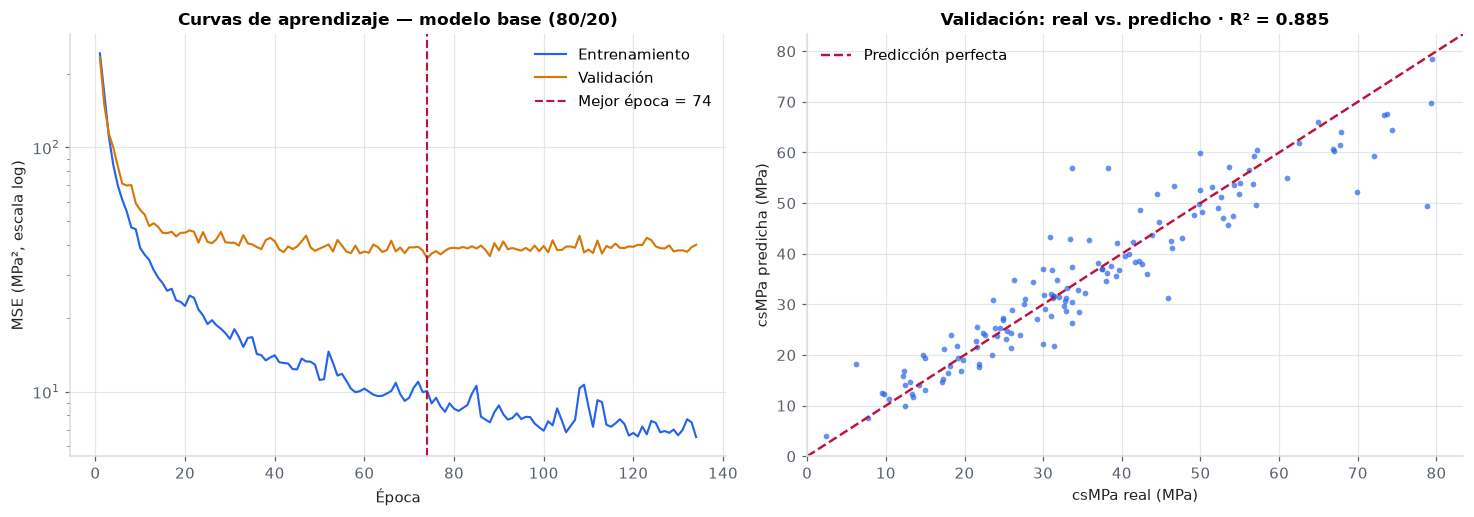

Brecha validación − entrenamiento: +27.56 MPa² (+362 % del MSE de entrenamiento)
Épocas ejecutadas después de la mejor: 60
Pérdida de validación — en la mejor época: 35.17 MPa² · en la última: 39.94 MPa²
Pérdida de entrenamiento — en la mejor época: 10.07 MPa² · en la última: 6.53 MPa²


In [26]:
tabla_base = tabla_train_valid(res_base)
sigma2_base = res_base["esc_y"].scale_[0] ** 2
mse_val_desde_loss = res_base["mejor_val_loss"] * sigma2_base
assert math.isclose(tabla_base.loc["Validación (20 %)", "MSE"], mse_val_desde_loss, rel_tol=1e-3), \
    "Las métricas en MPa no coinciden con la pérdida escalada: revisar la inversión del objetivo"
print(f"Comprobación de escala: MSE de validación invertido = {tabla_base.loc['Validación (20 %)', 'MSE']:.3f} MPa² · "
      f"σ² × mejor pérdida = {mse_val_desde_loss:.3f} MPa² ✔")
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")
display(tabla_base.round(3))


def graficar_curvas(ax, res, titulo):
    s2 = res["esc_y"].scale_[0] ** 2
    h = res["historial"]
    ax.plot(h["epoca"], h["train_loss"] * s2, color=PALETA[0], lw=1.4, label="Entrenamiento")
    ax.plot(h["epoca"], h["val_loss"] * s2, color=PALETA[1], lw=1.4, label="Validación")
    ax.axvline(res["mejor_epoca"], color=PALETA[3], ls="--", lw=1.4, label=f"Mejor época = {res['mejor_epoca']}")
    ax.set_yscale("log"); ax.set_xlabel("Época"); ax.set_ylabel("MSE (MPa², escala log)")
    ax.set_title(titulo); ax.legend()


def graficar_real_vs_pred(ax, y_real, y_pred, titulo):
    ax.scatter(y_real, y_pred, s=14, alpha=0.7, color=PALETA[0], linewidths=0)
    lim = [0, max(np.max(y_real), np.max(y_pred)) * 1.05]
    ax.plot(lim, lim, color=PALETA[3], ls="--", lw=1.6, label="Predicción perfecta")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("csMPa real (MPa)"); ax.set_ylabel("csMPa predicha (MPa)")
    ax.set_title(titulo); ax.legend(loc="upper left")


pred_valid_base = invertir_y(res_base["esc_y"], predecir(res_base["modelo"], res_base["X_va"]))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
graficar_curvas(axes[0], res_base, "Curvas de aprendizaje — modelo base (80/20)")
graficar_real_vs_pred(axes[1], df_valid[TARGET].to_numpy(), pred_valid_base,
                      f"Validación: real vs. predicho · R² = {tabla_base.loc['Validación (20 %)', 'R2']:.3f}")
fig.tight_layout(); plt.show()

h = res_base["historial"]
mse_tr, mse_va = tabla_base["MSE"]
print(f"Brecha validación − entrenamiento: {mse_va - mse_tr:+.2f} MPa² "
      f"({100 * (mse_va - mse_tr) / mse_tr:+.0f} % del MSE de entrenamiento)")
print(f"Épocas ejecutadas después de la mejor: {res_base['epocas_ejecutadas'] - res_base['mejor_epoca']}")
print(f"Pérdida de validación — en la mejor época: {h['val_loss'].min() * sigma2_base:.2f} MPa² · "
      f"en la última: {h['val_loss'].iloc[-1] * sigma2_base:.2f} MPa²")
print(f"Pérdida de entrenamiento — en la mejor época: {h['train_loss'].iloc[res_base['mejor_epoca'] - 1] * sigma2_base:.2f} MPa² · "
      f"en la última: {h['train_loss'].iloc[-1] * sigma2_base:.2f} MPa²")

### 7.5 Interpretación del modelo base

**Magnitud del error.** En validación, el modelo base obtiene un **MSE de 35.17 MPa²** (RMSE 5.93 MPa, MAE 4.05 MPa,
R² 0.885). Frente a una resistencia media de ≈ 36 MPa en `df_valid`, el error típico es de unos 4–6 MPa (≈ 11–16 %),
y la red explica ≈ 88 % de la varianza. Es muy inferior a los ≈ 295 MPa² de predecir siempre la media: la red aprende
señal real desde la primera configuración.

**Diagnóstico: sobreajuste claro, no subajuste.** El MSE de entrenamiento (7.61 MPa², R² 0.972) es casi **cinco veces
menor** que el de validación: brecha de +27.56 MPa², +362 % del MSE de entrenamiento. Las curvas muestran la firma
clásica. Después de la mejor época (74), la pérdida de entrenamiento sigue bajando (de 10.07 a 6.53 MPa² en la última
época), mientras la de validación **sube** (de 35.17 a 39.94 MPa²). Con ~6 800 parámetros y 564 filas, la red
memoriza parte del entrenamiento. No hay subajuste: el error de validación es bajo en términos absolutos (R² 0.885).

**El early stopping cumplió su función.** El entrenamiento siguió 60 épocas más (la paciencia) sin mejorar y luego se
restauraron los pesos de la época 74. Usar el modelo de la última época habría empeorado el MSE de validación en
+4.77 MPa² (≈ +14 %). Este diagnóstico de sobreajuste motiva que la etapa B evalúe regularización explícita (dropout y
weight decay).

**Advertencia metodológica.** Estas métricas de validación son algo optimistas, porque `df_valid` también eligió la
época de parada (sección 4.1). Por eso las comparaciones entre configuraciones se hacen con K-Fold, donde la época se
elige con un subconjunto interno.

---
# 8. *Baselines* y experimentos con validación cruzada K-Fold (Parte 6)

### 8.1 Protocolo para una comparación justa

- **Mismas particiones para todo:** 5 folds fijos (`KFold(shuffle=True, random_state=42)`) y, dentro de cada fold,
  el mismo 15 % interno para early stopping. Todas las configuraciones y *baselines* ven exactamente las mismas filas.
- **Todo se ajusta desde cero en cada fold:** preprocesador, escalador del objetivo y red. No se reutiliza nada
  ajustado en otro fold.
- **Misma semilla por fold** (`SEED + fold`) para la inicialización y el orden de los *batches*: dos configuraciones
  con la misma arquitectura parten de los mismos pesos, de modo que la diferencia se debe al factor que se cambió.
- **Un factor a la vez** respecto a una referencia, para poder atribuir el efecto.
- **Métricas en MPa sobre el fold de validación**, que no participa ni en el ajuste ni en la parada.

**Diseño en dos etapas.**

- **Etapa A — representación de los datos** (arquitectura base fija): E0 originales → E1 `log1p(age)` →
  E2 + variables derivadas → E3 + indicadores. Es un diseño **acumulativo**: cada paso añade una única decisión al
  anterior, así que su diferencia mide el efecto de esa decisión.
- **Etapa B — red y entrenamiento** sobre la representación ganadora de A: anchura (E4 más estrecha, E5 más ancha),
  regularización (E6 dropout, E7 weight decay) y optimización (E8 learning rate, E9 batch size).

**Regla de selección (definida antes de ver los resultados).** Se prioriza el MSE medio de validación cruzada. Como
con 5 folds las diferencias pequeñas pueden ser ruido, se usa la **regla de 1 error estándar pareado**: entre las
configuraciones cuyo MSE no supera al del mejor en más de un error estándar de la diferencia fold a fold, se elige
**la más simple** (en A, la que añade menos variables; en B, la referencia sin cambios). Una variante sólo se adopta
si mejora **más que el ruido entre folds**. Las otras métricas (RMSE, MAE, R²) se usan como complemento.

> **Costo.** La celda mide e imprime el tiempo de cada configuración. Si el entorno fuera demasiado lento, la forma
> declarada de reducir costo es `MODO_RAPIDO` (2 folds, pocas épocas), que se identifica en todas las salidas y **no
> es una validación cruzada completa**.

In [27]:
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
PARTICIONES = []
for k, (idx_tr, idx_va) in enumerate(kfold.split(df_limpio), start=1):
    idx_fit, idx_es = train_test_split(idx_tr, test_size=FRACCION_ES, random_state=SEED + k)
    PARTICIONES.append({"fold": k, "fit": np.sort(idx_fit), "es": np.sort(idx_es), "val": idx_va})

# Comprobaciones: los tres subconjuntos son disjuntos y cada fila es validación exactamente una vez
for p in PARTICIONES:
    a, b, c = set(p["fit"]), set(p["es"]), set(p["val"])
    assert not (a & b or a & c or b & c) and len(a | b | c) == len(df_limpio)
assert sorted(np.concatenate([p["val"] for p in PARTICIONES])) == list(range(len(df_limpio)))

display(pd.DataFrame([{"fold": p["fold"], "ajuste (fit)": len(p["fit"]), "early stopping": len(p["es"]),
                       "validación": len(p["val"])} for p in PARTICIONES]).set_index("fold"))

,ajuste (fit),early stopping,validación
fold,,,
1,479,85,141
2,479,85,141
3,479,85,141
4,479,85,141
5,479,85,141


In [28]:
def evaluar_cv(config):
    """Evalúa una configuración (MLP o baseline) en los folds fijos. Todo se ajusta desde cero en cada fold."""
    filas, oof = [], np.full(len(df_limpio), np.nan)
    t0 = time.perf_counter()
    for p in PARTICIONES:
        df_fit, df_es, df_val = df_limpio.iloc[p["fit"]], df_limpio.iloc[p["es"]], df_limpio.iloc[p["val"]]
        prep, esc_y = ajustar_transformaciones(df_fit, config["conjunto"])      # sólo filas de ajuste
        X_fit, y_fit = transformar_X(prep, df_fit), transformar_y(esc_y, df_fit)
        X_val = transformar_X(prep, df_val)
        extra = {}
        if config["tipo"] == "mlp":
            X_es, y_es = transformar_X(prep, df_es), transformar_y(esc_y, df_es)
            res = entrenar_modelo(config, X_fit, y_fit, X_es, y_es, seed=SEED + p["fold"])
            pred = invertir_y(esc_y, predecir(res["modelo"], X_val))
            extra = {"mejor_epoca": res["mejor_epoca"], "epocas_ejecutadas": res["epocas_ejecutadas"],
                     "agoto_epocas": res["agoto_epocas"], "batches_por_epoca": res["batches_por_epoca"],
                     "parametros": contar_parametros(res["modelo"])}
        elif config["tipo"] == "media":
            pred = np.full(len(df_val), df_fit[TARGET].mean())
        elif config["tipo"] == "lineal":
            reg = LinearRegression().fit(X_fit, y_fit.ravel())
            pred = invertir_y(esc_y, reg.predict(X_val))
        else:
            raise ValueError(config["tipo"])
        oof[p["val"]] = pred
        filas.append({"fold": p["fold"], **metricas_mpa(df_val[TARGET], pred), **extra})
    assert np.isfinite(oof).all(), "Faltan predicciones fuera de fold"
    return {"config": config, "folds": pd.DataFrame(filas).set_index("fold"), "oof": oof,
            "segundos": time.perf_counter() - t0}


resultados = {}


def ejecutar(configs):
    for c in configs:
        if c["nombre"] in resultados:          # misma configuración, mismos folds y semillas ⇒ mismo resultado
            continue
        r = evaluar_cv(c)
        resultados[c["nombre"]] = r
        f = r["folds"]
        print(f"{c['nombre']:<52} MSE = {f['MSE'].mean():8.2f} ± {f['MSE'].std(ddof=1):6.2f} MPa² · {r['segundos']:6.1f} s")


def resumir(nombres):
    filas = []
    for nombre in nombres:
        r = resultados[nombre]
        f, c = r["folds"], r["config"]
        fila = {"Configuración": nombre, "Variables": c["conjunto"],
                "Modelo": "MLP " + "-".join(map(str, c["capas"])) if c["tipo"] == "mlp" else c["tipo"],
                "MSE (media)": f["MSE"].mean(), "MSE (DE)": f["MSE"].std(ddof=1),
                "RMSE": f["RMSE"].mean(), "MAE": f["MAE"].mean(), "R²": f["R2"].mean()}
        if c["tipo"] == "mlp":
            fila.update({"lr": c["lr"], "batch": c["batch_size"], "dropout": c["dropout"], "weight decay": c["weight_decay"],
                         "parámetros": int(f["parametros"].iloc[0]), "mejor época (mediana)": f["mejor_epoca"].median(),
                         "folds que agotaron épocas": int(f["agoto_epocas"].sum()), "segundos": r["segundos"]})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Configuración")


def comparar_pareado(referencia, nombres):
    """Diferencia de MSE fold a fold respecto a una referencia (negativo = mejor que la referencia)."""
    ref = resultados[referencia]["folds"]["MSE"].to_numpy()
    filas = []
    for n in nombres:
        d = resultados[n]["folds"]["MSE"].to_numpy() - ref
        ee = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
        filas.append({"Configuración": n, "Δ MSE medio (MPa²)": d.mean(), "EE de la diferencia": ee,
                      "Δ / EE": d.mean() / ee if ee and ee > 0 else np.nan,
                      "folds en que mejora": f"{int((d < 0).sum())}/{len(d)}"})
    return pd.DataFrame(filas).set_index("Configuración")


def regla_1ee(orden):
    """Regla de 1 error estándar pareado. `orden` va de la opción más simple a la más compleja."""
    medias = {n: resultados[n]["folds"]["MSE"].mean() for n in orden}
    mejor = min(medias, key=medias.get)
    ref = resultados[mejor]["folds"]["MSE"].to_numpy()
    candidatos = []
    for n in orden:
        d = resultados[n]["folds"]["MSE"].to_numpy() - ref
        ee = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else 0.0
        if d.mean() <= ee:
            candidatos.append(n)
    elegido = candidatos[0]
    print(f"Menor MSE medio: {mejor} ({medias[mejor]:.2f} MPa²)")
    print(f"Dentro de 1 EE pareado del mejor: {candidatos}")
    print(f"➜ Seleccionada (la más simple entre ellas): {elegido} ({medias[elegido]:.2f} MPa²)")
    return elegido

### 8.2 *Baselines*

Sirven como referencia, no como sustitutos de la red:

- **B0 · Media:** predice siempre la media de `csMPa` de las filas de ajuste. Cualquier modelo útil debe superarlo
  ampliamente.
- **B1 · Regresión lineal (8 originales).** Mide cuánto de la resistencia es explicable de forma lineal.
- **B2 · Regresión lineal (`log1p(age)` + derivadas).** Separa el efecto de la **ingeniería de variables** del de la
  **red**: si la MLP sólo superara a B1 pero no a B2, la ventaja vendría de las variables y no de la no linealidad.

In [29]:
BASELINES = [
    {"nombre": "B0 · Media", "tipo": "media", "conjunto": "originales"},
    {"nombre": "B1 · Regresión lineal (8 originales)", "tipo": "lineal", "conjunto": "originales"},
    {"nombre": "B2 · Regresión lineal (log1p(age) + derivadas)", "tipo": "lineal", "conjunto": "derivadas"},
]
ejecutar(BASELINES)
display(resumir([b["nombre"] for b in BASELINES]).round(3))

B0 · Media                                           MSE =   280.44 ±  35.07 MPa² ·    0.1 s
B1 · Regresión lineal (8 originales)                 MSE =   108.31 ±   9.74 MPa² ·    0.1 s


B2 · Regresión lineal (log1p(age) + derivadas)       MSE =    51.77 ±   5.82 MPa² ·    0.1 s


,Variables,Modelo,MSE (media),MSE (DE),RMSE,MAE,R²
Configuración,,,,,,,
B0 · Media,originales,media,280.4420,35.0710,16.7180,13.6560,-0.0130
B1 · Regresión lineal (8 originales),originales,lineal,108.3080,9.7370,10.3980,8.1840,0.6020
B2 · Regresión lineal (log1p(age) + derivadas),derivadas,lineal,51.7710,5.8180,7.1860,5.5120,0.8120


### 8.3 Etapa A — representación de los datos (E0–E3)

**Hipótesis previas** (derivadas del EDA, sección 2.10; se registran antes de ver los resultados):

- **E1 · `log1p(age)`:** debería ayudar, porque la edad es la variable más asimétrica y su relación con la
  resistencia es monótona pero no lineal. Podría **no** ayudar si la red ya aproxima bien esa curva con la edad
  estandarizada.
- **E2 · + cementante total, agua/cementante y agua/cemento:** son las variables más correlacionadas con la
  resistencia, pero la red podría construirlas por sí sola, y añaden entradas redundantes con pocas observaciones.
- **E3 · + indicadores de presencia:** su aporte es el más dudoso. La información "es cero" ya está en la variable
  continua, y una red con ReLU puede representar ese quiebre.

In [30]:
EXP_A = [
    {**CONFIG_BASE},
    {**CONFIG_BASE, "nombre": "E1 · log1p(age)", "conjunto": "log_edad"},
    {**CONFIG_BASE, "nombre": "E2 · log1p(age) + derivadas", "conjunto": "derivadas"},
    {**CONFIG_BASE, "nombre": "E3 · E2 + indicadores de presencia", "conjunto": "derivadas_indicadores"},
]
t0_a = time.perf_counter()
ejecutar(EXP_A)
print(f"Tiempo total de la etapa A: {time.perf_counter() - t0_a:.0f} s")
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")

NOMBRES_A = [c["nombre"] for c in EXP_A]
display(resumir(NOMBRES_A).round(3))
print("Comparación pareada contra E0 (Δ < 0: mejor que la base):")
display(comparar_pareado(CONFIG_BASE["nombre"], NOMBRES_A).round(3))
print("Comparación pareada de cada paso contra el anterior (efecto marginal de cada decisión):")
display(pd.concat([comparar_pareado(NOMBRES_A[i - 1], [NOMBRES_A[i]]) for i in range(1, len(NOMBRES_A))]).round(3))
GANADOR_A = regla_1ee(NOMBRES_A)

E0 · Base (8 originales)                             MSE =    30.86 ±   3.78 MPa² ·   12.7 s


E1 · log1p(age)                                      MSE =    25.03 ±   0.91 MPa² ·    8.3 s


E2 · log1p(age) + derivadas                          MSE =    25.82 ±   3.16 MPa² ·    9.6 s


E3 · E2 + indicadores de presencia                   MSE =    25.04 ±   2.82 MPa² ·   10.0 s
Tiempo total de la etapa A: 41 s


,Variables,Modelo,MSE (media),MSE (DE),RMSE,MAE,R²,lr,batch,dropout,weight decay,parámetros,mejor época (mediana),folds que agotaron épocas,segundos
Configuración,,,,,,,,,,,,,,,
E0 · Base (8 originales),originales,MLP 64-64-32,30.8630,3.7750,5.5480,4.0010,0.8850,0.0010,32,0.0000,0.0000,6849,77.0000,0,12.7180
E1 · log1p(age),log_edad,MLP 64-64-32,25.0310,0.9080,5.0020,3.5890,0.9080,0.0010,32,0.0000,0.0000,6849,43.0000,0,8.3010
E2 · log1p(age) + derivadas,derivadas,MLP 64-64-32,25.8190,3.1620,5.0740,3.4960,0.9060,0.0010,32,0.0000,0.0000,7041,83.0000,0,9.6080
E3 · E2 + indicadores de presencia,derivadas_indicadores,MLP 64-64-32,25.0410,2.8160,4.9980,3.3980,0.9090,0.0010,32,0.0000,0.0000,7233,52.0000,0,10.0110


Comparación pareada contra E0 (Δ < 0: mejor que la base):


,Δ MSE medio (MPa²),EE de la diferencia,Δ / EE,folds en que mejora
Configuración,,,,
E0 · Base (8 originales),0.0000,0.0000,NaN,0/5
E1 · log1p(age),-5.8320,1.9670,-2.9650,5/5
E2 · log1p(age) + derivadas,-5.0440,2.8190,-1.7890,4/5
E3 · E2 + indicadores de presencia,-5.8220,2.6690,-2.1810,4/5


Comparación pareada de cada paso contra el anterior (efecto marginal de cada decisión):


,Δ MSE medio (MPa²),EE de la diferencia,Δ / EE,folds en que mejora
Configuración,,,,
E1 · log1p(age),-5.8320,1.9670,-2.9650,5/5
E2 · log1p(age) + derivadas,0.7880,1.2870,0.6130,3/5
E3 · E2 + indicadores de presencia,-0.7780,0.4850,-1.6070,3/5


Menor MSE medio: E1 · log1p(age) (25.03 MPa²)
Dentro de 1 EE pareado del mejor: ['E1 · log1p(age)', 'E2 · log1p(age) + derivadas', 'E3 · E2 + indicadores de presencia']
➜ Seleccionada (la más simple entre ellas): E1 · log1p(age) (25.03 MPa²)


### 8.4 Interpretación de la etapa A

**E0 → E1, `log1p(age)`: hipótesis confirmada, y es la mejora más grande de todo el estudio.** El MSE baja de
30.86 ± 3.78 a 25.03 ± 0.91 MPa² (−5.83 MPa², ≈ −19 %). La diferencia es casi tres errores estándar
(Δ/EE = −2.97) y se repite en **los 5 folds**. Además, la variabilidad entre folds se reduce a la cuarta parte
(DE de 3.78 a 0.91): con la edad en escala logarítmica, la red no sólo acierta más, sino de forma más estable. Era lo
que anticipaba el EDA: la edad es la variable más asimétrica, y su relación con la resistencia es monótona pero no
lineal.

**E1 → E2, variables derivadas: hipótesis rechazada para la red; resultado desfavorable.** Añadir cementante total,
agua/cementante y agua/cemento **no mejoró**: el MSE sube ligeramente, de 25.03 a 25.82 MPa² (+0.79; Δ/EE = 0.61,
dentro del ruido), y la DE entre folds se triplica (0.91 → 3.16). Aunque estas variables son las más correlacionadas
con la resistencia, la red ya puede construir esas proporciones a partir de `water`, `cement`, `slag` y `flyash`.
Con ~480 filas de ajuste, tres entradas redundantes parecen añadir más inestabilidad que información.

**E2 → E3, indicadores de presencia: sin ganancia neta.** Recuperan lo perdido en E2 (−0.78 MPa², Δ/EE = −1.61, 3/5
folds), pero E3 (25.04) queda prácticamente igual que E1 (25.03), con siete variables más.

**Selección.** E1 tiene el menor MSE medio, y E2 y E3 están dentro de 1 EE pareado de él. La regla elige
**E1 · `log1p(age)`**, que aquí es a la vez la mejor y la más simple. Las variables derivadas y los indicadores no se
descartaron por conveniencia: se midieron y no aportaron.

**Contraste con los *baselines* lineales.** Para la regresión lineal, la ingeniería de variables es decisiva: el MSE
cae de 108.31 (B1) a 51.77 MPa² (B2), menos de la mitad. Para la red, en cambio, sólo importa `log1p(age)`. Es
evidencia de que la MLP ya captura por sí sola, gracias a su no linealidad, las relaciones que el modelo lineal sólo
aprovecha si se le dan construidas. En B2, `log1p(age)` y las derivadas entran juntas, así que esta comparación no
separa su efecto dentro del modelo lineal.

### 8.5 Etapa B — arquitectura, regularización y optimización (E4–E9)

Todas las variantes parten de la configuración ganadora de la etapa A y cambian **un solo** factor.

**Hipótesis previas:**

- **E4 · red más estrecha (32-32-16):** con ~480 filas de ajuste, menos parámetros podrían generalizar igual o mejor.
  También podría quedarse corta (underfitting).
- **E5 · red más ancha (128-128-64):** más capacidad; con early stopping, el riesgo de sobreajuste se controla en
  parte, pero con tan pocas filas no se espera una gran mejora.
- **E6 · dropout 0.1 y E7 · weight decay 10⁻³:** regularización explícita. Si el modelo base sobreajusta (brecha
  train/val de la sección 7), deberían ayudar; si no, podrían introducir sesgo.
- **E8 · learning rate 3·10⁻³:** converge en menos épocas, pero puede volver más ruidosa la validación.
- **E9 · batch 64:** la mitad de pasos por época y gradientes menos ruidosos; responde a la instrucción de
  experimentar con el `batch_size`.

En esta etapa, la referencia es la ganadora de A, y una variante sólo se adopta si mejora más de 1 EE pareado.

In [31]:
CONFIG_REF = resultados[GANADOR_A]["config"]
etiqueta_ref = GANADOR_A.split(" · ")[0]
EXP_B = [
    {**CONFIG_REF, "nombre": f"E4 · {etiqueta_ref} + red 32-32-16", "capas": (32, 32, 16)},
    {**CONFIG_REF, "nombre": f"E5 · {etiqueta_ref} + red 128-128-64", "capas": (128, 128, 64)},
    {**CONFIG_REF, "nombre": f"E6 · {etiqueta_ref} + dropout 0.1", "dropout": 0.1},
    {**CONFIG_REF, "nombre": f"E7 · {etiqueta_ref} + weight decay 1e-3", "weight_decay": 1e-3},
    {**CONFIG_REF, "nombre": f"E8 · {etiqueta_ref} + lr 3e-3", "lr": 3e-3},
    {**CONFIG_REF, "nombre": f"E9 · {etiqueta_ref} + batch 64", "batch_size": 64},
]
print("Referencia de la etapa B:", GANADOR_A)
t0_b = time.perf_counter()
ejecutar(EXP_B)
print(f"Tiempo total de la etapa B: {time.perf_counter() - t0_b:.0f} s")
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")

NOMBRES_B = [GANADOR_A] + [c["nombre"] for c in EXP_B]
display(resumir(NOMBRES_B).round(3))
print(f"Comparación pareada contra la referencia ({GANADOR_A}):")
display(comparar_pareado(GANADOR_A, NOMBRES_B).round(3))
SELECCION = regla_1ee(NOMBRES_B)
CONFIG_FINAL = resultados[SELECCION]["config"]

Referencia de la etapa B: E1 · log1p(age)


E4 · E1 + red 32-32-16                               MSE =    27.44 ±   5.27 MPa² ·    9.1 s


E5 · E1 + red 128-128-64                             MSE =    26.17 ±   3.45 MPa² ·   11.9 s


E6 · E1 + dropout 0.1                                MSE =    25.57 ±   2.31 MPa² ·   15.5 s


E7 · E1 + weight decay 1e-3                          MSE =    23.87 ±   0.66 MPa² ·   11.3 s


...

E9 · E1 + batch 64                                   MSE =    24.38 ±   1.15 MPa² ·    5.7 s
Tiempo total de la etapa B: 65 s


,Variables,Modelo,MSE (media),MSE (DE),RMSE,MAE,R²,lr,batch,dropout,weight decay,parámetros,mejor época (mediana),folds que agotaron épocas,segundos
Configuración,,,,,,,,,,,,,,,
E1 · log1p(age),log_edad,MLP 64-64-32,25.0310,0.9080,5.0020,3.5890,0.9080,0.0010,32,0.0000,0.0000,6849,43.0000,0,8.3010
E4 · E1 + red 32-32-16,log_edad,MLP 32-32-16,27.4430,5.2710,5.2180,3.7600,0.9000,0.0010,32,0.0000,0.0000,1889,87.0000,0,9.0740
E5 · E1 + red 128-128-64,log_edad,MLP 128-128-64,26.1720,3.4460,5.1080,3.3990,0.9040,0.0010,32,0.0000,0.0000,25985,87.0000,0,11.9060
E6 · E1 + dropout 0.1,log_edad,MLP 64-64-32,25.5740,2.3110,5.0530,3.5820,0.9070,0.0010,32,0.1000,0.0000,6849,170.0000,0,15.5020
E7 · E1 + weight decay 1e-3,log_edad,MLP 64-64-32,23.8660,0.6560,4.8850,3.4160,0.9130,0.0010,32,0.0000,0.0010,6849,64.0000,0,11.3480
E8 · E1 + lr 3e-3,log_edad,MLP 64-64-32,24.3960,1.4650,4.9370,3.4120,0.9100,0.0030,32,0.0000,0.0000,6849,58.0000,0,11.2010
E9 · E1 + batch 64,log_edad,MLP 64-64-32,24.3770,1.1480,4.9360,3.4700,0.9110,0.0010,64,0.0000,0.0000,6849,59.0000,0,5.6570


Comparación pareada contra la referencia (E1 · log1p(age)):


,Δ MSE medio (MPa²),EE de la diferencia,Δ / EE,folds en que mejora
Configuración,,,,
E1 · log1p(age),0.0000,0.0000,NaN,0/5
E4 · E1 + red 32-32-16,2.4120,2.6280,0.9180,2/5
E5 · E1 + red 128-128-64,1.1420,1.5230,0.7500,2/5
E6 · E1 + dropout 0.1,0.5430,1.0480,0.5180,2/5
E7 · E1 + weight decay 1e-3,-1.1650,0.3540,-3.2930,5/5
E8 · E1 + lr 3e-3,-0.6340,0.7980,-0.7950,3/5
E9 · E1 + batch 64,-0.6540,0.4760,-1.3730,3/5


Menor MSE medio: E7 · E1 + weight decay 1e-3 (23.87 MPa²)
Dentro de 1 EE pareado del mejor: ['E7 · E1 + weight decay 1e-3', 'E8 · E1 + lr 3e-3']
➜ Seleccionada (la más simple entre ellas): E7 · E1 + weight decay 1e-3 (23.87 MPa²)


### 8.6 Tabla comparativa consolidada (configuración → MSE de validación)

,¿seleccionada?,Variables,Modelo,MSE (media),MSE (DE),RMSE,MAE,R²,lr,batch,dropout,weight decay,parámetros,mejor época (mediana),folds que agotaron épocas,segundos
Configuración,,,,,,,,,,,,,,,,
E7 · E1 + weight decay 1e-3,✔,log_edad,MLP 64-64-32,23.8660,0.6560,4.8850,3.4160,0.9130,0.0010,32.0000,0.0000,0.0010,"6,849.0000",64.0000,0.0000,11.3480
E9 · E1 + batch 64,,log_edad,MLP 64-64-32,24.3770,1.1480,4.9360,3.4700,0.9110,0.0010,64.0000,0.0000,0.0000,"6,849.0000",59.0000,0.0000,5.6570
E8 · E1 + lr 3e-3,,log_edad,MLP 64-64-32,24.3960,1.4650,4.9370,3.4120,0.9100,0.0030,32.0000,0.0000,0.0000,"6,849.0000",58.0000,0.0000,11.2010
E1 · log1p(age),,log_edad,MLP 64-64-32,25.0310,0.9080,5.0020,3.5890,0.9080,0.0010,32.0000,0.0000,0.0000,"6,849.0000",43.0000,0.0000,8.3010
E3 · E2 + indicadores de presencia,,derivadas_indicadores,MLP 64-64-32,25.0410,2.8160,4.9980,3.3980,0.9090,0.0010,32.0000,0.0000,0.0000,"7,233.0000",52.0000,0.0000,10.0110
E6 · E1 + dropout 0.1,,log_edad,MLP 64-64-32,25.5740,2.3110,5.0530,3.5820,0.9070,0.0010,32.0000,0.1000,0.0000,"6,849.0000",170.0000,0.0000,15.5020
E2 · log1p(age) + derivadas,,derivadas,MLP 64-64-32,25.8190,3.1620,5.0740,3.4960,0.9060,0.0010,32.0000,0.0000,0.0000,"7,041.0000",83.0000,0.0000,9.6080
E5 · E1 + red 128-128-64,,log_edad,MLP 128-128-64,26.1720,3.4460,5.1080,3.3990,0.9040,0.0010,32.0000,0.0000,0.0000,"25,985.0000",87.0000,0.0000,11.9060
E4 · E1 + red 32-32-16,,log_edad,MLP 32-32-16,27.4430,5.2710,5.2180,3.7600,0.9000,0.0010,32.0000,0.0000,0.0000,"1,889.0000",87.0000,0.0000,9.0740


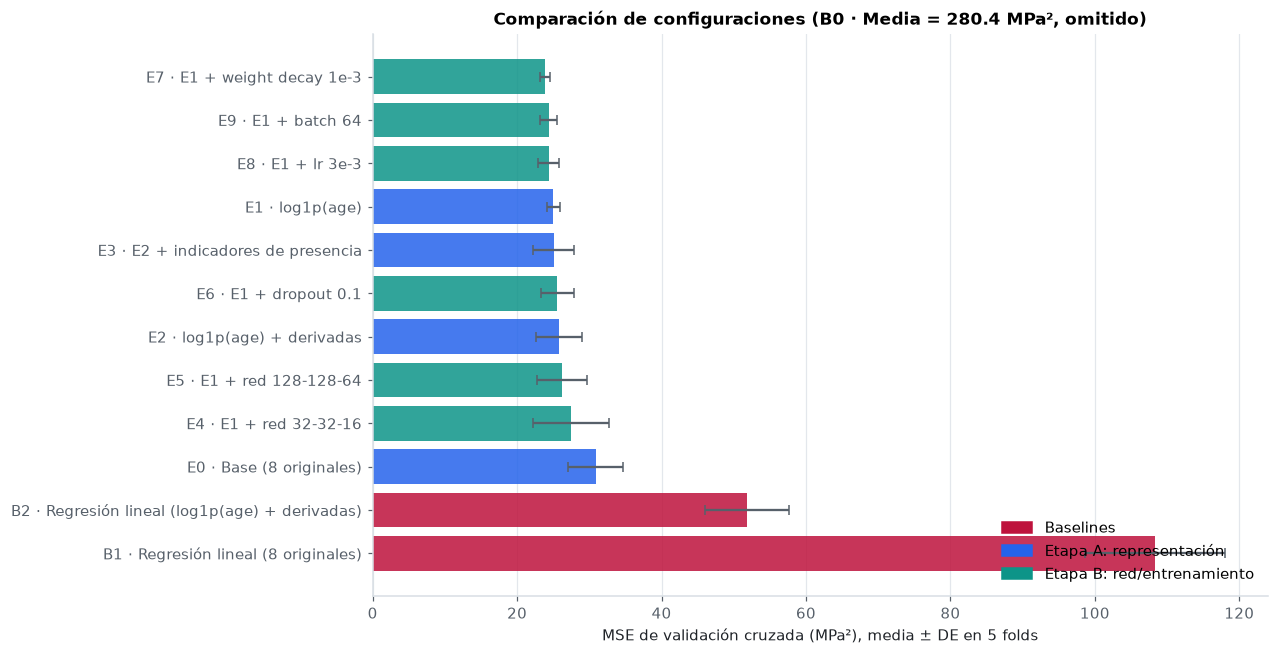

In [32]:
NOMBRES_BASELINES = [b["nombre"] for b in BASELINES]
tabla_total = resumir(NOMBRES_BASELINES + NOMBRES_A + [c["nombre"] for c in EXP_B]).sort_values("MSE (media)")
tabla_total.insert(0, "¿seleccionada?", ["✔" if n == SELECCION else "" for n in tabla_total.index])
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")
display(tabla_total.round(3))

graf = tabla_total.drop(index="B0 · Media")            # B0 (≈ varianza del objetivo) aplastaría la escala del gráfico
colores = [PALETA[3] if n.startswith("B") else (PALETA[0] if n in NOMBRES_A else PALETA[2]) for n in graf.index]
fig, ax = plt.subplots(figsize=(10.5, 0.42 * len(graf) + 1.6))
ax.barh(graf.index, graf["MSE (media)"], xerr=graf["MSE (DE)"], color=colores, alpha=0.85,
        error_kw=dict(ecolor=TINTA_SUAVE, capsize=3))
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"MSE de validación cruzada (MPa²), media ± DE en {N_FOLDS} folds")
ax.set_title(f"Comparación de configuraciones (B0 · Media = {tabla_total.loc['B0 · Media', 'MSE (media)']:.1f} MPa², omitido)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETA[3], label="Baselines"), Patch(color=PALETA[0], label="Etapa A: representación"),
                   Patch(color=PALETA[2], label="Etapa B: red/entrenamiento")], loc="lower right")
plt.show()

### 8.7 Interpretación de la etapa B y de la tabla consolidada

**Capacidad de la red: ni más ni menos ayuda.**
- **E4, red más estrecha (32-32-16, 1 889 parámetros):** empeora +2.41 MPa², y es la configuración más inestable de
  la etapa (DE 5.27).
- **E5, red más ancha (128-128-64, 25 985 parámetros):** empeora +1.14 MPa².

Ninguna de las dos diferencias supera 1 EE (Δ/EE de 0.92 y 0.75), y ambas sólo mejoran en 2 de 5 folds. Con ~480 filas
de ajuste, la arquitectura de partida (64-64-32) ya está en una zona adecuada: multiplicar los parámetros por cuatro
no aporta, y reducirlos a menos de un tercio cuesta algo de precisión.

**Regularización: el weight decay es la única variante que mejora más allá del ruido.**
- **E7, weight decay 10⁻³:** baja el MSE a **23.87 ± 0.66 MPa²** (−1.17 frente a E1). Es más de tres errores
  estándar (Δ/EE = −3.29) y mejora en **los 5 folds**; además, tiene la menor variabilidad de todas las
  configuraciones. Es coherente con el sobreajuste diagnosticado en la sección 7: penalizar la magnitud de los pesos
  suaviza la función aprendida.
- **E6, dropout 0.1:** no ayudó (+0.54, 2/5 folds) y retrasó la convergencia (mejor época mediana 170, frente a 43).
  Con una red tan pequeña, apagar neuronas al azar parece añadir ruido sin un beneficio de generalización medible.

**Optimización: efectos pequeños.**
- **E8, learning rate 3·10⁻³:** −0.63 MPa² (Δ/EE = −0.80, 3/5 folds), dentro del ruido.
- **E9, batch 64:** −0.65 MPa² (Δ/EE = −1.37, 3/5 folds). Supera ligeramente 1 EE frente a la referencia, pero
  queda claramente por detrás de E7.

El learning rate de partida (10⁻³) y el batch de 32 eran elecciones razonables.

**Selección y validez de la comparación.** La referencia E1 **no** queda dentro de 1 EE de E7, así que el cambio se
adopta. E8 sí está dentro de 1 EE de E7, pero ambas variantes modifican un único hiperparámetro respecto a la
referencia; ninguna es "más simple", y la regla se queda con E7, la de menor MSE (también la primera de las dos en el
orden declarado). La configuración final es, por tanto, **E7:
`log1p(age)` + red 64-64-32 + weight decay 10⁻³**. **Ninguna configuración agotó `MAX_EPOCAS` en ningún fold**, así
que ninguna comparación está sesgada por falta de épocas. Todas tardaron del orden de segundos a decenas de segundos
por validación cruzada en CPU, de modo que el costo no condiciona ninguna decisión.

**¿La red supera a los *baselines*? Sí, con amplitud.** E7 obtiene 23.87 MPa² frente a 51.77 de la regresión lineal
con variables derivadas (B2) y 108.31 de la lineal con las originales (B1): **−54 % y −78 %** de MSE, con R² de 0.913
frente a 0.812 y 0.602. Como B2 ya recibe las mismas transformaciones, esta ventaja se debe a la **no linealidad** de
la red, no sólo a la ingeniería de variables.

**Limitación.** El MSE de validación cruzada de E7 es algo optimista: se eligió entre 10 configuraciones de red con
esos mismos folds. La única estimación completamente independiente es el puntaje de Kaggle.

---
# 9. Evaluación final del modelo seleccionado

La evaluación final usa las **predicciones fuera de fold** (*out-of-fold*): cada fila de `df_limpio` se predice con
el modelo del fold en que fue validación, es decir, con un modelo que **nunca la vio** ni para ajustar ni para elegir
la época. Esto permite analizar los errores sobre las 705 filas sin usar `test.csv`.

In [33]:
res_sel = resultados[SELECCION]
print("Configuración seleccionada:", SELECCION)
print({k: v for k, v in CONFIG_FINAL.items() if k != "nombre"})
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")
print("\nMétricas por fold (validación, MPa):")
display(res_sel["folds"].round(3))

oof_metricas = metricas_mpa(df_limpio[TARGET], res_sel["oof"])
print("Métricas globales fuera de fold (705 filas):", {k: round(v, 3) for k, v in oof_metricas.items()})
print("\nComparación pareada del modelo seleccionado contra baselines y modelo base (Δ < 0: el seleccionado es mejor):")
contrincantes = [n for n in NOMBRES_BASELINES + [CONFIG_BASE["nombre"]] if n != SELECCION]
comp_final = comparar_pareado(SELECCION, contrincantes)
comp_final["Δ MSE medio (MPa²)"] *= -1   # reorientar: MSE del seleccionado − MSE del contrincante
comp_final = comp_final.rename(columns={"Δ MSE medio (MPa²)": "MSE seleccionado − MSE contrincante (MPa²)",
                                        "folds en que mejora": "folds en que el contrincante gana"})
comp_final["Δ / EE"] *= -1
display(comp_final.round(3))

Configuración seleccionada: E7 · E1 + weight decay 1e-3
{'tipo': 'mlp', 'conjunto': 'log_edad', 'capas': (64, 64, 32), 'activacion': 'relu', 'dropout': 0.0, 'lr': 0.001, 'weight_decay': 0.001, 'batch_size': 32}

Métricas por fold (validación, MPa):


,MSE,RMSE,MAE,R2,mejor_epoca,epocas_ejecutadas,agoto_epocas,batches_por_epoca,parametros
fold,,,,,,,,,
1,23.4060,4.8380,3.4500,0.9230,47,107,False,15,6849
2,24.6220,4.9620,3.4550,0.9120,64,124,False,15,6849
3,23.0520,4.8010,3.3930,0.8950,162,222,False,15,6849
4,24.3910,4.9390,3.3410,0.9150,63,123,False,15,6849
5,23.8580,4.8840,3.4430,0.9190,169,229,False,15,6849


Métricas globales fuera de fold (705 filas): {'MSE': 23.866, 'RMSE': 4.885, 'MAE': 3.416, 'R2': 0.914}

Comparación pareada del modelo seleccionado contra baselines y modelo base (Δ < 0: el seleccionado es mejor):


,MSE seleccionado − MSE contrincante (MPa²),EE de la diferencia,Δ / EE,folds en que el contrincante gana
Configuración,,,,
B0 · Media,-256.5770,15.5400,-16.5110,0/5
B1 · Regresión lineal (8 originales),-84.4430,4.5320,-18.6340,0/5
B2 · Regresión lineal (log1p(age) + derivadas),-27.9060,2.5680,-10.8660,0/5
E0 · Base (8 originales),-6.9980,1.8620,-3.7590,0/5


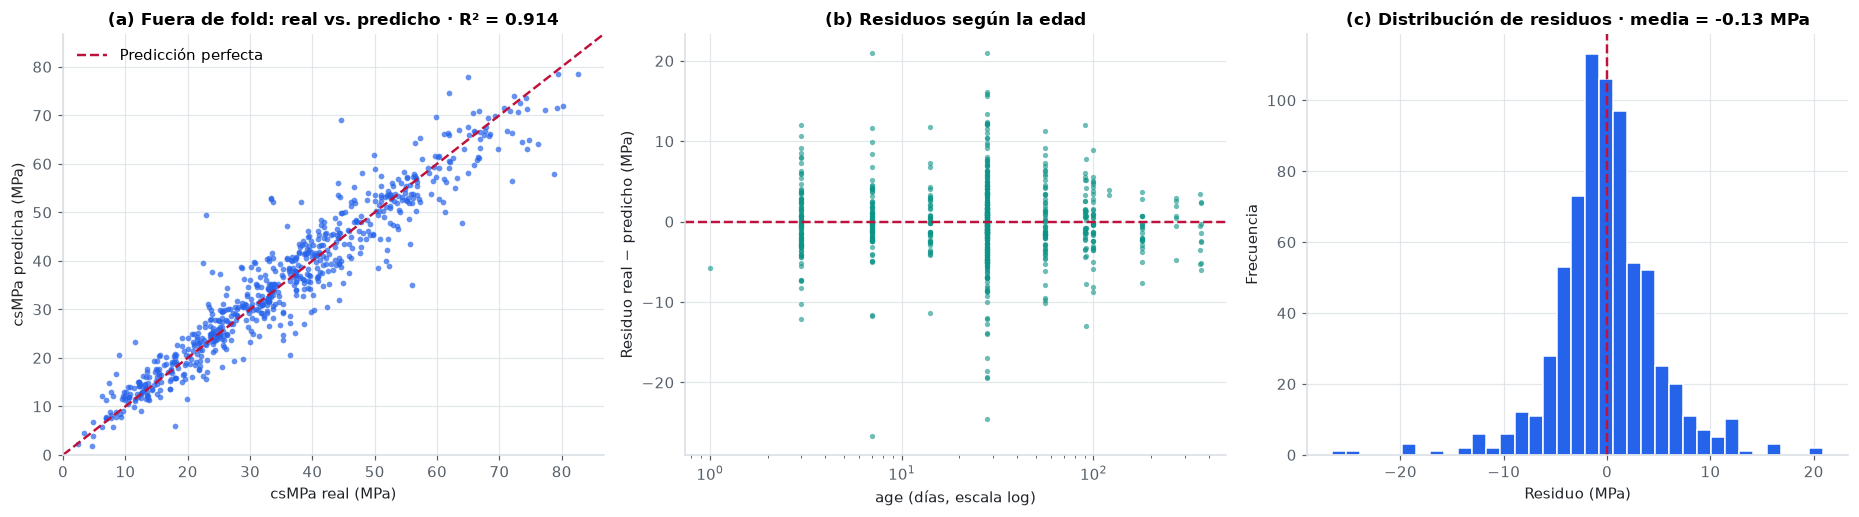

Error fuera de fold según la edad de ensayo:


age,1,3,7,14,28,56,90,91,100,120,180,270,360,365
n,1.0000,93.0000,81.0000,45.0000,295.0000,65.0000,27.0000,14.0000,41.0000,2.0000,22.0000,7.0000,4.0000,8.0000
MAE,5.7800,3.2400,3.0200,2.6600,3.9600,3.5000,2.6100,3.6600,2.7600,3.6100,2.2100,1.9800,3.2200,2.8100
MSE,33.4300,18.3100,26.9200,13.3200,31.8900,19.7000,12.4600,26.2200,12.9900,13.1400,7.9100,6.1100,13.1100,11.0500


MAE fuera de fold en filas con réplica de predictores: 6.87 MPa (n = 17) · resto: 3.33 MPa
Residuos fuera de fold: media -0.13 MPa · desviación 4.89 MPa · |residuo| > 10 MPa en 39 filas (5.5 %)
Las 5 filas con mayor error absoluto:


,Row ID,age,csMPa,predicho,residuo,en_replica
221,224,7,22.9000,49.5300,-26.6300,True
661,676,28,44.5200,69.0100,-24.4900,False
311,317,28,78.8000,57.8600,20.9400,False
19,19,7,55.9000,34.9700,20.9300,True
359,366,28,33.4200,52.8500,-19.4300,False


In [34]:
residuos = df_limpio[TARGET].to_numpy() - res_sel["oof"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
graficar_real_vs_pred(axes[0], df_limpio[TARGET].to_numpy(), res_sel["oof"],
                      f"(a) Fuera de fold: real vs. predicho · R² = {oof_metricas['R2']:.3f}")
axes[1].scatter(df_limpio["age"], residuos, s=12, alpha=0.6, color=PALETA[2], linewidths=0)
axes[1].axhline(0, color=PALETA[3], lw=1.6, ls="--"); axes[1].set_xscale("log")
axes[1].set_xlabel("age (días, escala log)"); axes[1].set_ylabel("Residuo real − predicho (MPa)")
axes[1].set_title("(b) Residuos según la edad")
axes[2].hist(residuos, bins=35, color=PALETA[0], edgecolor="white")
axes[2].axvline(0, color=PALETA[3], lw=1.6, ls="--")
axes[2].set_xlabel("Residuo (MPa)"); axes[2].set_ylabel("Frecuencia")
axes[2].set_title(f"(c) Distribución de residuos · media = {residuos.mean():+.2f} MPa")
fig.tight_layout(); plt.show()

err_edad = (pd.DataFrame({"age": df_limpio["age"], "abs_err": np.abs(residuos), "err2": residuos ** 2})
            .groupby("age").agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), MSE=("err2", "mean")))
print("Error fuera de fold según la edad de ensayo:")
display(err_edad.round(2).T)

# Las filas con el mismo vector de predictores y distinta resistencia fijan un piso de error para ESAS filas
en_replica = df_limpio.groupby(PREDICTORES)[TARGET].transform("size") > 1
print(f"MAE fuera de fold en filas con réplica de predictores: {np.abs(residuos[en_replica.to_numpy()]).mean():.2f} MPa "
      f"(n = {int(en_replica.sum())}) · resto: {np.abs(residuos[~en_replica.to_numpy()]).mean():.2f} MPa")

grandes = np.abs(residuos) > 10
print(f"Residuos fuera de fold: media {residuos.mean():+.2f} MPa · desviación {residuos.std(ddof=1):.2f} MPa · "
      f"|residuo| > 10 MPa en {int(grandes.sum())} filas ({100 * grandes.mean():.1f} %)")
print("Las 5 filas con mayor error absoluto:")
display(df_limpio.assign(predicho=res_sel["oof"], residuo=residuos, en_replica=en_replica.to_numpy())
        .loc[np.argsort(-np.abs(residuos))[:5], [ID_COL, "age", TARGET, "predicho", "residuo", "en_replica"]].round(2))

**Curvas de aprendizaje del modelo seleccionado.** Para discutir el sobreajuste de la configuración elegida, se
entrena en la misma partición 80/20 de la sección 7 y se compara con el modelo base. Es una visualización
diagnóstica: la selección ya se hizo con K-Fold y esta partición no cambia la decisión.

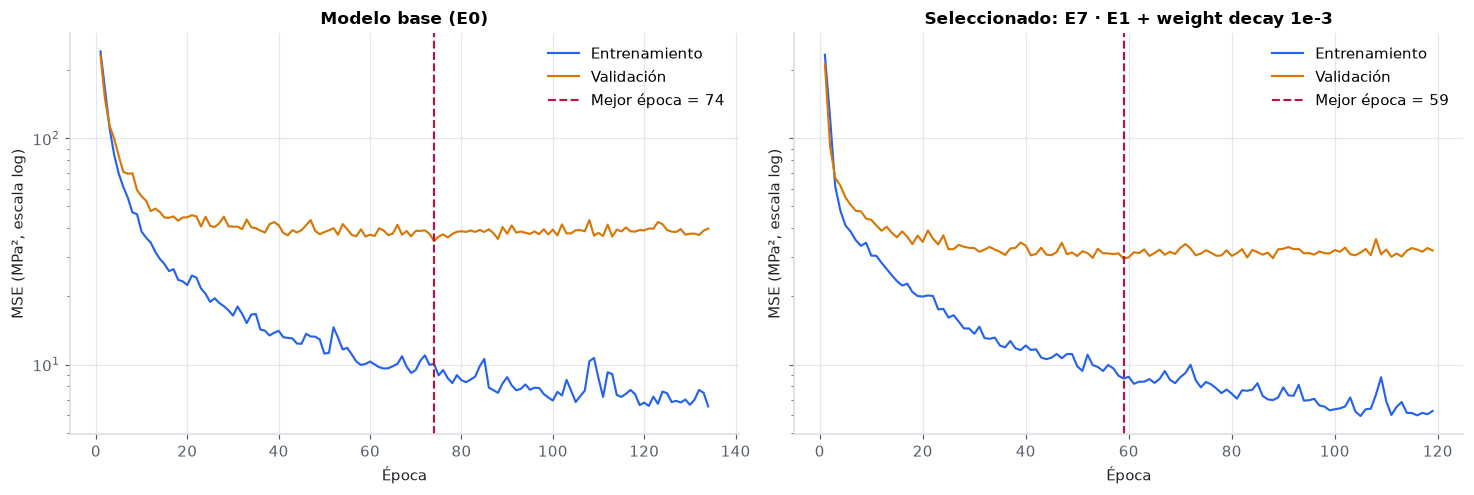

MSE   RMSE    MAE     R2
E0 · Base    Entrenamiento (80 %)  7.6100 2.7590 1.9440 0.9720
             Validación (20 %)    35.1650 5.9300 4.0520 0.8850
Seleccionado Entrenamiento (80 %)  8.3460 2.8890 2.1320 0.9690
             Validación (20 %)    29.4080 5.4230 3.4800 0.9040

E0 · Base    : mejor época 74 de 134 · validación en la mejor 35.17 MPa² vs en la última 39.94 MPa² · entrenamiento en la mejor 10.07 MPa²
Seleccionado : mejor época 59 de 119 · validación en la mejor 29.41 MPa² vs en la última 31.93 MPa² · entrenamiento en la mejor 8.67 MPa²


In [35]:
res_sel_split = res_base if SELECCION == CONFIG_BASE["nombre"] else ajustar_en_split_80_20(CONFIG_FINAL)
tabla_sel = tabla_train_valid(res_sel_split)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
graficar_curvas(axes[0], res_base, "Modelo base (E0)")
graficar_curvas(axes[1], res_sel_split, f"Seleccionado: {SELECCION}")
fig.tight_layout(); plt.show()
display(pd.concat({"E0 · Base": tabla_base, "Seleccionado": tabla_sel}).round(3))
for nombre, r in [("E0 · Base", res_base), ("Seleccionado", res_sel_split)]:
    s2 = r["esc_y"].scale_[0] ** 2
    h_ = r["historial"]
    print(f"{nombre:<13}: mejor época {r['mejor_epoca']} de {r['epocas_ejecutadas']} · validación en la mejor "
          f"{h_['val_loss'].min() * s2:.2f} MPa² vs en la última {h_['val_loss'].iloc[-1] * s2:.2f} MPa² · "
          f"entrenamiento en la mejor {h_['train_loss'].iloc[r['mejor_epoca'] - 1] * s2:.2f} MPa²")

### 9.1 Interpretación de la evaluación final

**Estabilidad.** El MSE de E7 varía muy poco entre folds, de 23.05 a 24.62 MPa² (DE 0.66): ningún fold es claramente
más difícil, y el resultado no depende de una partición afortunada. Sobre las 705 predicciones fuera de fold, el
desempeño global es **MSE 23.87 MPa², RMSE 4.89 MPa, MAE 3.42 MPa y R² 0.914**. Llama la atención que la mejor época
forme dos grupos (47–64 en tres folds y 162–169 en dos) sin que el MSE cambie: con sólo 85 filas para el early
stopping, la curva de validación interna es ruidosa y el punto de parada exacto es poco preciso, aunque el
desempeño resultante sea estable.

**Ventaja sobre los *baselines*: consistente en todos los folds.** En la comparación pareada, E7 gana en los 5 folds a
los tres *baselines* y al modelo base:
- −256.6 MPa² frente a la media;
- −84.4 frente a B1;
- −27.9 frente a B2;
- −7.0 frente a E0 (Δ/EE = −3.76).

**Dónde se equivoca.** Los residuos están centrados (media −0.13 MPa, desviación 4.89 MPa), así que **no hay sesgo
sistemático**. El 5.5 % de las filas (39) tiene un error mayor de 10 MPa. Por edad no aparece una tendencia monótona.
El MAE es mayor a 28 días (3.96 MPa, n = 295), la edad con más filas y con las mezclas más heterogéneas, y menor a
edades largas (2.21 a 180 días, 1.98 a 270), donde la resistencia ya varía menos. El valor de 1 día (5.78 MPa) se
basa en una sola fila y no es interpretable.

**Ruido irreducible: confirmado en los datos.** En las 17 filas cuya mezcla y edad tienen réplica con otra resistencia,
el MAE es **6.87 MPa, el doble** que en el resto (3.33 MPa). La tabla de mayores errores lo ilustra. Dos de los cinco
casos (`Row ID` 224 y 19) son **la misma mezcla ensayada a 7 días**, con 22.9 y 55.9 MPa reales (sección 2.3). Ante
entradas idénticas, ningún modelo puede acertar ambas: este error no es un defecto de la red, sino un piso impuesto por
la variabilidad del ensayo.

**Curvas de aprendizaje (diagnóstico en la partición 80/20).** El weight decay reduce el sobreajuste, pero no lo
elimina:
- la brecha entrenamiento–validación baja de 27.56 MPa² en E0 a 21.06 MPa² en el seleccionado (8.35 frente a
  29.41);
- tras la mejor época (59 de 119), la validación sube menos que en E0: +2.52 MPa², frente a +4.77.

Una brecha de este tamaño es esperable con ~560 filas y una red de ~6 800 parámetros. Como esta validación también
eligió la época, su MSE (29.41) es sólo indicativo. La estimación de referencia del modelo es la de K-Fold
(23.87 ± 0.66 MPa²).

---
# 10. Reentrenamiento, predicción sobre `test.csv` y submission (Parte 7)

### 10.1 Regla para entrenar el modelo final

El enunciado permite, opcionalmente, reentrenar con todo `train.csv`. Se hace, porque con ~700 filas cada
observación cuenta. El problema es que, sin validación, ya no hay early stopping. **Regla documentada (sin usar
test):**

- En el K-Fold, cada fold detuvo el entrenamiento en su mejor época, tras `mejor_epoca × batches_por_epoca` **pasos
  de optimización**.
- El modelo final se entrena durante la **mediana de esos pasos**, convertida a épocas con el número de *batches*
  del conjunto completo. Se usan pasos y no épocas porque, con más filas, cada época contiene más actualizaciones;
  repetir el número de épocas sobreentrenaría proporcionalmente.
- El preprocesador y el escalador del objetivo se reajustan **con todo `df_limpio`** (el nuevo conjunto de
  entrenamiento) y a `test.csv` sólo se le aplica `.transform()`.

Es una aproximación razonable, no exacta. Por eso se declara como limitación.

In [36]:
f_sel = resultados[SELECCION]["folds"]
pasos_optimos = (f_sel["mejor_epoca"] * f_sel["batches_por_epoca"]).to_numpy()
batches_completo = math.ceil(len(df_limpio) / CONFIG_FINAL["batch_size"])
EPOCAS_FINALES = max(1, int(round(np.median(pasos_optimos) / batches_completo)))
print(f"Pasos óptimos por fold: {pasos_optimos.tolist()} · mediana = {np.median(pasos_optimos):.0f}")
print(f"Batches por época con {len(df_limpio)} filas: {batches_completo} ⇒ EPOCAS_FINALES = {EPOCAS_FINALES}")

prep_final, esc_y_final = ajustar_transformaciones(df_limpio, CONFIG_FINAL["conjunto"])
X_completo, y_completo = transformar_X(prep_final, df_limpio), transformar_y(esc_y_final, df_limpio)
t0 = time.perf_counter()
modelo_final, perdidas_final, _ = entrenar_epocas_fijas(CONFIG_FINAL, X_completo, y_completo, EPOCAS_FINALES, seed=SEED)
print(f"Modelo final entrenado en {time.perf_counter() - t0:.1f} s · parámetros: {contar_parametros(modelo_final):,}")

ajuste_final = metricas_mpa(df_limpio[TARGET], invertir_y(esc_y_final, predecir(modelo_final, X_completo)))
print("Ajuste sobre sus propios datos de entrenamiento (control de cordura, NO es una estimación de generalización):",
      {k: round(v, 3) for k, v in ajuste_final.items()})
print(f"Referencia de generalización (K-Fold): MSE = {f_sel['MSE'].mean():.2f} ± {f_sel['MSE'].std(ddof=1):.2f} MPa²")

Pasos óptimos por fold: [705, 960, 2430, 945, 2535] · mediana = 960
Batches por época con 705 filas: 23 ⇒ EPOCAS_FINALES = 42


Modelo final entrenado en 0.8 s · parámetros: 6,849
Ajuste sobre sus propios datos de entrenamiento (control de cordura, NO es una estimación de generalización): {'MSE': 13.492, 'RMSE': 3.673, 'MAE': 2.785, 'R2': 0.952}
Referencia de generalización (K-Fold): MSE = 23.87 ± 0.66 MPa²


### 10.2 Predicciones sobre `test.csv`

Se aplica exactamente el mismo pipeline (mismas variables derivadas y mismo escalador ajustado con `df_limpio`), se
invierte la escala del objetivo y se comprueba que las predicciones sean finitas, que haya una por fila de test y que
estén asociadas a su `Row ID` (tomado de la **columna**, no del índice de pandas).

Predicciones: 309 · rango [4.84, 73.91] MPa · media 34.72 MPa (train: 35.54)
Predicciones negativas: 0 · por encima del máximo de train (82.6 MPa): 0


,Row ID,csMPa
0,721,30.9823
1,722,28.5540
2,723,23.4007
3,724,60.6755
4,725,47.3138


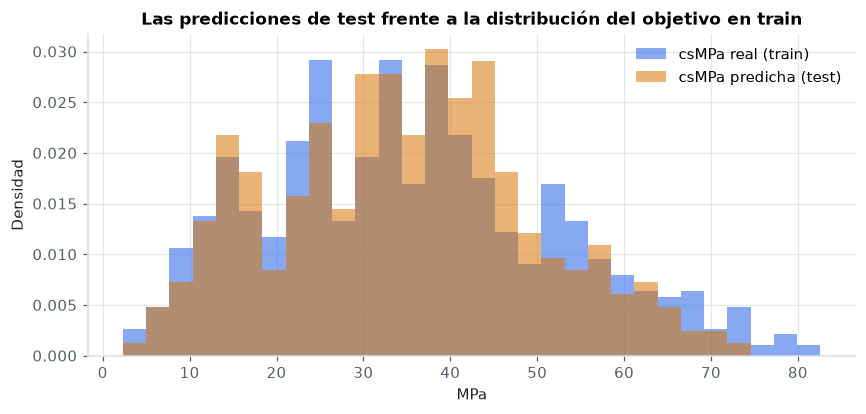

In [37]:
X_test = transformar_X(prep_final, test_raw)
assert X_test.shape == (len(test_raw), len(CONJUNTOS_FEATURES[CONFIG_FINAL["conjunto"]]))
pred_test = invertir_y(esc_y_final, predecir(modelo_final, X_test))
assert pred_test.shape == (len(test_raw),) and np.isfinite(pred_test).all()

predicciones_test = pd.DataFrame({ID_COL: test_raw[ID_COL].to_numpy(), TARGET: pred_test})
assert predicciones_test[ID_COL].is_unique
assert (predicciones_test[ID_COL].to_numpy() == test_raw[ID_COL].to_numpy()).all()

print(f"Predicciones: {len(predicciones_test)} · rango [{pred_test.min():.2f}, {pred_test.max():.2f}] MPa · "
      f"media {pred_test.mean():.2f} MPa (train: {df_limpio[TARGET].mean():.2f})")
print(f"Predicciones negativas: {int((pred_test < 0).sum())} · por encima del máximo de train "
      f"({df_limpio[TARGET].max():.1f} MPa): {int((pred_test > df_limpio[TARGET].max()).sum())}")
display(predicciones_test.head())

fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.histogram_bin_edges(np.concatenate([df_limpio[TARGET], pred_test]), bins=30)
ax.hist(df_limpio[TARGET], bins=bordes, density=True, alpha=0.55, color=PALETA[0], label="csMPa real (train)")
ax.hist(pred_test, bins=bordes, density=True, alpha=0.55, color=PALETA[1], label="csMPa predicha (test)")
ax.set_xlabel("MPa"); ax.set_ylabel("Densidad"); ax.legend()
ax.set_title("Las predicciones de test frente a la distribución del objetivo en train")
plt.show()

### 10.3 `submission.csv`: formato y confirmación en Kaggle

**Formato con el que se construye el archivo (según la evidencia disponible):** el enunciado pide predecir sobre
`test.csv` y construir el archivo "con el mismo formato de `sample_submission.csv`". Por eso se toman de la
plantilla **los nombres y el orden de las columnas** (`Row ID`, `csMPa`) y se escribe **una predicción por cada fila
de `test.csv`, en su mismo orden**. La plantilla local no sirve para fijar el número de filas ni los identificadores
(sección 1.3: 10 filas con `Row ID` de train).

**Qué hace la celda siguiente:** valida la submission en memoria, la escribe como `submission.csv` en la raíz del
proyecto (`CARPETA_SALIDA`, sección 1.1),
la **relee desde el disco** y comprueba que el archivo releído supera las mismas validaciones y contiene exactamente
las predicciones del modelo final. En `MODO_RAPIDO` **no** escribe el archivo, para que una prueba rápida nunca
sobrescriba la submission de la ejecución completa.

**`FORMATO_KAGGLE_CONFIRMADO = True`: el formato está confirmado.** La bandera registra si el formato se verificó
con la competencia. Valió `False` mientras sólo se contaba con la plantilla local. Se cambió a `True` porque:

1. La página de la competencia indica las columnas **`Row ID`** y **`csMPa`**, las mismas de este archivo.
2. Kaggle **procesó y puntuó** este mismo `submission.csv` (309 filas, `Row ID` 721–1029, en el orden de `test.csv`)
   con estado *Complete*. Es decir, aceptó su número de filas, sus identificadores y sus columnas (sección 10.4).

In [38]:
FORMATO_KAGGLE_CONFIRMADO = True         # confirmado: Kaggle procesó y puntuó este archivo (sección 10.4)
N_FILAS_ESPERADAS = len(test_raw)        # una fila por fila de test.csv (309), formato aceptado por Kaggle
RUTA_SUBMISSION = os.path.join(CARPETA_SALIDA, "submission.csv")


def validar_submission(sub):
    if list(sub.columns) != list(sample_sub.columns):     # sin las columnas esperadas no se puede validar el resto
        return [f"columnas {list(sub.columns)} ≠ plantilla {list(sample_sub.columns)}"]
    errores = []
    if len(sub) != N_FILAS_ESPERADAS:
        errores.append(f"{len(sub)} filas ≠ {N_FILAS_ESPERADAS} esperadas")
    if sub[ID_COL].duplicated().any():
        errores.append("Row ID duplicados")
    if set(sub[ID_COL]) != set(test_raw[ID_COL]):
        errores.append("los Row ID no son exactamente los de test.csv")
    elif len(sub) == len(test_raw) and not (sub[ID_COL].to_numpy() == test_raw[ID_COL].to_numpy()).all():
        errores.append("los Row ID no siguen el orden de test.csv")
    valores = pd.to_numeric(sub[TARGET], errors="coerce")
    if valores.isna().any() or not np.isfinite(valores).all():
        errores.append("predicciones faltantes o no finitas")
    return errores


submission = predicciones_test[list(sample_sub.columns)].copy()
errores = validar_submission(submission)
print("Validación de la submission en memoria:", "✅ sin errores" if not errores else errores)
if errores:
    raise ValueError(f"La submission no supera la validación: {errores}")

if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: NO se escribe submission.csv (las predicciones de una prueba rápida no son válidas).")
else:
    submission.to_csv(RUTA_SUBMISSION, index=False)
    releida = pd.read_csv(RUTA_SUBMISSION)
    errores_disco = validar_submission(releida)
    assert errores_disco == [], f"El archivo escrito no supera la validación: {errores_disco}"
    assert list(releida.columns) == [ID_COL, TARGET] and releida.shape == (len(test_raw), 2)   # sin índice ni columnas extra
    assert np.allclose(releida[TARGET].to_numpy(), pred_test, rtol=0, atol=1e-9), "El archivo no contiene las predicciones del modelo final"
    print(f"✅ submission.csv escrito y releído: {RUTA_SUBMISSION}")
    print(f"   {releida.shape[0]} filas × {releida.shape[1]} columnas {list(releida.columns)} · Row ID "
          f"{releida[ID_COL].min()}–{releida[ID_COL].max()} en el orden de test.csv · predicciones = modelo final")
    if FORMATO_KAGGLE_CONFIRMADO:
        print("   Formato confirmado en Kaggle: la competencia procesó y puntuó este archivo (sección 10.4).")
        if EN_COLAB:
            try:
                from google.colab import files
                files.download(RUTA_SUBMISSION)
            except Exception as e:   # la descarga depende del navegador; el archivo ya quedó en disco
                print("   Descarga automática no disponible:", e)
    else:
        print("⚠️  FORMATO_KAGGLE_CONFIRMADO = False: el formato oficial (nº de filas e identificadores) NO se ha "
              "verificado en Kaggle. Comprobar los puntos de la celda anterior antes de subir el archivo.")

Validación de la submission en memoria: ✅ sin errores
✅ submission.csv escrito y releído: .\submission.csv
   309 filas × 2 columnas ['Row ID', 'csMPa'] · Row ID 721–1029 en el orden de test.csv · predicciones = modelo final
   Formato confirmado en Kaggle: la competencia procesó y puntuó este archivo (sección 10.4).


### 10.4 Evaluación externa en Kaggle

El archivo `submission.csv` generado en la sección 10.3 se envió a la competencia. La tabla registra lo que muestra
Kaggle en las capturas de evidencia del repositorio.

| Concepto | Valor |
|---|---|
| Competencia | [Concrete Strength - Regression](https://www.kaggle.com/competitions/concrete-strength-regression) |
| Archivo enviado | `submission.csv` (el de la sección 10.3, sin modificar) |
| Descripción del envío | "MLP en PyTorch con transformacion log1p(age) y weight decay" |
| Estado | **Complete (after deadline)** |
| **Public Score** | **24.81485** |
| Métrica | MSE (MPa²); menor es mejor |
| Fecha | No se registra: las capturas sólo muestran un tiempo relativo ("32s ago", "3m ago") |

**Evidencia:** [listado de envíos con el Public Score](https://github.com/jmcastrom/workshop-2-concrete-strength-mlp/blob/main/docs/evidence/screenshot01.png) y [detalle del envío con el control de selección para la
evaluación final](https://github.com/jmcastrom/workshop-2-concrete-strength-mlp/blob/main/docs/evidence/screenshot02.png) (`docs/evidence/` del repositorio).

**Interpretación.** El Public Score (24.81 MPa², es decir, un RMSE ≈ 4.98 MPa) es una evaluación **externa** sobre
datos que no participaron en ninguna decisión del notebook. Queda **0.95 MPa² (≈ 4 %) por encima** del MSE de
validación cruzada del modelo seleccionado (23.87 ± 0.66 MPa²) y algo por encima del peor fold (24.62 MPa²). Es una
diferencia pequeña y en la dirección esperada: la estimación interna era algo optimista, porque la configuración se
eligió entre diez con esos mismos folds. Kaggle confirma así el orden de magnitud del error estimado, pero es una sola
medición sobre el conjunto de prueba y **no valida por sí sola** cada conclusión de los experimentos: las
comparaciones entre configuraciones se apoyan en la validación cruzada. La celda siguiente calcula esta diferencia a
partir de los resultados del notebook.

**Limitaciones de esta evaluación.**
- El envío se procesó **después de la fecha límite** de la competencia.
- En la página de envíos aparecen **0 de 2 envíos seleccionados** para la evaluación final, y la casilla de selección
  de este envío está sin marcar.
- El panel de detalle muestra también "Private score: 24.81485" para este envío. Al ser un envío posterior al cierre
  y no seleccionado, no se presenta aquí como un puntaje final del equipo en la competencia ni como una posición en
  el leaderboard.

In [39]:
PUNTAJE_PUBLICO_KAGGLE = 24.81485   # Public Score (MSE, MPa²) mostrado por Kaggle para submission.csv (sección 10.4)

mse_cv_sel = resultados[SELECCION]["folds"]["MSE"]
print(f"Public Score de Kaggle      : {PUNTAJE_PUBLICO_KAGGLE:.5f} MPa² (RMSE ≈ {math.sqrt(PUNTAJE_PUBLICO_KAGGLE):.2f} MPa)")
print(f"MSE de validación cruzada   : {mse_cv_sel.mean():.2f} ± {mse_cv_sel.std(ddof=1):.2f} MPa² "
      f"(folds: {mse_cv_sel.min():.2f}–{mse_cv_sel.max():.2f})")
print(f"Diferencia Kaggle − CV      : {PUNTAJE_PUBLICO_KAGGLE - mse_cv_sel.mean():+.2f} MPa² "
      f"({100 * (PUNTAJE_PUBLICO_KAGGLE / mse_cv_sel.mean() - 1):+.1f} %)")

Public Score de Kaggle      : 24.81485 MPa² (RMSE ≈ 4.98 MPa)
MSE de validación cruzada   : 23.87 ± 0.66 MPa² (folds: 23.05–24.62)
Diferencia Kaggle − CV      : +0.95 MPa² (+4.0 %)


---
# 11. Conclusiones

La celda siguiente reúne en una sola tabla los números en que deben apoyarse las conclusiones.

In [40]:
filas_resumen = {}
for n in NOMBRES_BASELINES + [CONFIG_BASE["nombre"], GANADOR_A, SELECCION]:
    f = resultados[n]["folds"]
    filas_resumen[n] = {"MSE CV (media)": f["MSE"].mean(), "MSE CV (DE)": f["MSE"].std(ddof=1),
                        "RMSE": f["RMSE"].mean(), "MAE": f["MAE"].mean(), "R²": f["R2"].mean()}
resumen_final = pd.DataFrame(filas_resumen).T
resumen_final = resumen_final[~resumen_final.index.duplicated()]
if MODO_RAPIDO:
    print("⚠️  MODO_RAPIDO: resultados no válidos para el informe.")
display(resumen_final.round(3))
print("Configuración seleccionada:", SELECCION, "· épocas del modelo final:", EPOCAS_FINALES)
print("submission.csv en disco:", os.path.isfile(RUTA_SUBMISSION),
      "· formato verificado en Kaggle:", FORMATO_KAGGLE_CONFIRMADO)
print("Puntaje público de Kaggle:", PUNTAJE_PUBLICO_KAGGLE if PUNTAJE_PUBLICO_KAGGLE is not None
      else "pendiente (requiere subir la submission)")

,MSE CV (media),MSE CV (DE),RMSE,MAE,R²
B0 · Media,280.4420,35.0710,16.7180,13.6560,-0.0130
B1 · Regresión lineal (8 originales),108.3080,9.7370,10.3980,8.1840,0.6020
B2 · Regresión lineal (log1p(age) + derivadas),51.7710,5.8180,7.1860,5.5120,0.8120
E0 · Base (8 originales),30.8630,3.7750,5.5480,4.0010,0.8850
E1 · log1p(age),25.0310,0.9080,5.0020,3.5890,0.9080
E7 · E1 + weight decay 1e-3,23.8660,0.6560,4.8850,3.4160,0.9130


Configuración seleccionada: E7 · E1 + weight decay 1e-3 · épocas del modelo final: 42
submission.csv en disco: True · formato verificado en Kaggle: True
Puntaje público de Kaggle: 24.81485


### Conclusiones

**Qué funcionó.** Una MLP de tres capas ocultas (64-64-32), implementada desde cero en PyTorch, predice la
resistencia del concreto con un **MSE de validación cruzada de 23.87 ± 0.66 MPa²** (RMSE ≈ 4.9 MPa, MAE ≈ 3.4 MPa,
R² 0.913). Supera en los cinco folds a todos los *baselines*: −54 % de MSE frente a la regresión lineal con las mismas
variables transformadas (51.77 MPa²) y −78 % frente a la lineal con las variables originales (108.31 MPa²). Por eso su
ventaja se atribuye a la no linealidad y no sólo al preprocesamiento. Dos decisiones explican la mejora sobre el
modelo base (30.86 MPa²), y ambas superan el ruido entre folds:
- **Representar la edad como `log1p(age)`** (−5.83 MPa², los 5 folds), la decisión con mayor efecto. Es la que
  anticipaba el EDA, que mostró una edad muy asimétrica con una relación monótona pero no lineal.
- **El weight decay de 10⁻³** (−1.17 MPa², los 5 folds), que atacó el sobreajuste visible en las curvas del modelo
  base: un MSE de entrenamiento casi cinco veces menor que el de validación.

**Qué no funcionó, y qué haríamos con más tiempo.** Varias hipótesis razonables no se confirmaron, y se reportan tal
cual:
- **Variables derivadas:** la relación agua/cementante, el cementante total y la relación agua/cemento, pese a ser las
  más correlacionadas con la resistencia, no mejoraron la red (+0.79 MPa² y más inestabilidad). Los indicadores de
  presencia tampoco aportaron frente a `log1p(age)` sola. La red ya construye esas proporciones, mientras que la
  regresión lineal sí las necesita: su MSE cae a la mitad con ellas.
- **Arquitectura:** ni una red más ancha ni una más estrecha mejoraron.
- **Dropout:** no ayudó.
- **Learning rate y batch size:** sus cambios quedaron dentro del ruido.

El análisis de residuos muestra un modelo sin sesgo (media −0.13 MPa) cuyo mayor error se concentra donde los propios
datos son contradictorios: en las réplicas de una misma mezcla con resistencias distintas, el MAE se duplica (6.87
frente a 3.33 MPa). Ese piso de ruido limita cualquier mejora futura. Con más tiempo, promediaríamos varias semillas o
los cinco modelos de los folds para reducir la varianza, probaríamos un early stopping con más filas o una regla de
parada menos ruidosa (sus épocas óptimas formaron dos grupos), exploraríamos otras activaciones, BatchNorm y una malla
fina de weight decay, y mediríamos con una validación agrupada por mezcla la generalización a dosificaciones nunca
vistas. La evaluación externa en Kaggle, la única independiente de nuestro proceso de selección, dio un **Public
Score de 24.81485 MPa²** (envío posterior al cierre, sección 10.4). Está cerca de la estimación de validación cruzada
(23.87 ± 0.66 MPa²) y es ligeramente peor, como cabía esperar por el optimismo de la selección.

### Limitaciones

1. **Muestra pequeña:** 705 filas únicas. Cada fold de validación tiene 141 filas, así que las diferencias entre
   configuraciones se leyeron frente a su error estándar pareado y no como cifras absolutas.
2. **Ruido irreducible:** hay mezclas idénticas ensayadas a la misma edad con resistencias muy distintas (hasta 33 MPa
   de diferencia), y en esas filas el error del modelo se duplica.
3. **Optimismo por selección:** la configuración final se eligió entre 10 configuraciones de red con los mismos folds,
   así que su MSE de validación cruzada (23.87 MPa²) es una estimación algo optimista.
4. **Early stopping con un subconjunto pequeño:** con 85 filas internas por fold, la época óptima es ruidosa (dos
   grupos: 47–64 y 162–169). El modelo final se entrenó 42 épocas, a partir de la mediana de pasos óptimos; es una
   aproximación, no un óptimo exacto.
5. **Sobreajuste residual:** incluso con weight decay, la red ajusta su entrenamiento bastante mejor que la
   validación (8.35 frente a 29.41 MPa² en la partición 80/20).
6. **Espacio explorado acotado a propósito:** una activación (ReLU), un optimizador (Adam), sin BatchNorm ni búsqueda
   sistemática; el objetivo fue un proceso razonado, no una búsqueda exhaustiva.
7. **Validación por filas:** ≈ 70 % de test comparte mezcla con train, así que la validación aleatoria refleja la
   partición de Kaggle, pero **no** mide la generalización a dosificaciones totalmente nuevas.
8. **Entorno de las cifras:** los resultados de este documento se obtuvieron en CPU con las versiones de la celda 0;
   otro entorno (p. ej., GPU) puede producir cifras ligeramente distintas.